<a href="https://colab.research.google.com/github/dalkhaseeb-D/at-risk-student-prediction/blob/main/OULAD_New_Approach_Corrected.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from pathlib import Path
import subprocess

PROJECT_DIR = Path("/content/oulad_baseline_review")

if not PROJECT_DIR.exists():
    subprocess.run(
        [
            "git", "clone",
            "https://github.com/dalkhaseeb-D/at-risk-student-prediction.git",
            str(PROJECT_DIR),
        ],
        check=True,
    )

commit = subprocess.check_output(
    ["git", "-C", str(PROJECT_DIR), "rev-parse", "HEAD"],
    text=True,
).strip()

print("GitHub version:", commit)
print("\nPython files:")
for path in sorted(PROJECT_DIR.rglob("*.py")):
    if ".git" not in path.parts:
        print(path.relative_to(PROJECT_DIR))

print("\nStep 1 completed.")

GitHub version: 9ce9278542c89ec878d2532eb7550e1aa39719be

Python files:
make_figures.py
run_experiment.py

Step 1 completed.


In [ ]:
import sys
import subprocess

requirements = PROJECT_DIR / "requirements.txt"

print("Installing project libraries...", flush=True)

subprocess.run(
    [
        sys.executable, "-m", "pip", "install",
        "-r", str(requirements)
    ],
    check=True
)

print("\nStep 2 completed: libraries installed.")

Installing project libraries...

Step 2 completed: libraries installed.


In [ ]:
import sys
import importlib
import json

if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

original = importlib.import_module("run_experiment")

DATA_DIR = PROJECT_DIR / "data"
RESULTS_DIR = PROJECT_DIR / "student_grouped_results"
FIGURES_DIR = PROJECT_DIR / "student_grouped_figures"

for folder in [DATA_DIR, RESULTS_DIR, FIGURES_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("1. Downloading OULAD data...", flush=True)
original.download_oulad(DATA_DIR)

print("\n2. Auditing the data...", flush=True)
tables = original.audit(DATA_DIR, RESULTS_DIR)

print("\n3. Building the original day-28 dataset...", flush=True)
model_data = original.build_dataset(
    tables, DATA_DIR, RESULTS_DIR
)

# At prediction time, the registration must already have started.
late_registration = model_data["date_registration"].gt(28)

print(
    "\nRegistrations starting after day 28:",
    int(late_registration.sum())
)

model_data = (
    model_data.loc[~late_registration]
    .reset_index(drop=True)
)

print("\nCorrected registrations:", len(model_data))
print("Unique students:", model_data["id_student"].nunique())
print(
    "At-risk percentage:",
    round(model_data["target_at_risk"].mean() * 100, 2)
)

model_data.to_csv(
    RESULTS_DIR / "day28_model_data.csv",
    index=False
)

print("\nStep 3 completed: data ready; no models trained.")

1. Downloading OULAD data...
[data] downloading OULAD from https://archive.ics.uci.edu/static/public/349/open%2Buniversity%2Blearning%2Banalytics%2Bdataset.zip

2. Auditing the data...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

                   File     Rows  Columns  Duplicate_Rows  NaN_naive_audit  Missing_as_?
            courses.csv       22        3               0                0             0
        assessments.csv      206        6               0                0            11
        studentInfo.csv    32593       12               0                0          1111
studentRegistration.csv    32593        5               0                0         22566
  studentAssessment.csv   173912        5               0                0           173
                vle.csv     6364        6               0                0         10486
         studentVle.csv 10655280        6          787170                0             0
               File              Column  Missing
        assessments                date       11
        studentInfo            imd_band     1111
studentRegistration   date_registration       45
studentRegistration date_unregistration    22521
  studentAssessment               score    

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

{
  "registrations": 32593,
  "withdrew_before_day28_excluded": 5055,
  "eligible_at_day28": 27538,
  "at_risk": 12153,
  "at_risk_pct": 44.13,
  "no_vle_activity_wk1_4": 1246,
  "unique_students": 24839,
  "students_with_multiple_registrations": 2578,
  "final_result_counts": {
    "Pass": 12361,
    "Fail": 7044,
    "Withdrawn": 5109,
    "Distinction": 3024
  }
}

Registrations starting after day 28: 16

Corrected registrations: 27522
Unique students: 24832
At-risk percentage: 44.12

Step 3 completed: data ready; no models trained.


In [ ]:
import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold

categorical_features = original.CATEGORICAL
numeric_features = original.PROFILE_NUMERIC + original.ENGAGEMENT

X = model_data[categorical_features + numeric_features].copy()
y = model_data["target_at_risk"].copy()
groups = model_data["id_student"].copy()

assert groups.notna().all(), "Some student IDs are missing."

splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Use the first fold, fixed before training or viewing performance.
train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()
y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

train_students = set(groups.iloc[train_idx])
test_students = set(groups.iloc[test_idx])
overlap = train_students & test_students

assert len(overlap) == 0, "Student overlap detected!"

split_summary = pd.DataFrame([
    {
        "Partition": "Train",
        "Registrations": len(train_idx),
        "Unique students": len(train_students),
        "At-risk %": round(y_train.mean() * 100, 2)
    },
    {
        "Partition": "Test",
        "Registrations": len(test_idx),
        "Unique students": len(test_students),
        "At-risk %": round(y_test.mean() * 100, 2)
    }
])

display(split_summary)
print("Students shared between train and test:", len(overlap))

assignments = model_data[original.KEYS].copy()
assignments["partition"] = ""
assignments.loc[X_train.index, "partition"] = "train"
assignments.loc[X_test.index, "partition"] = "test"

assignments.to_csv(
    RESULTS_DIR / "student_split_assignments.csv",
    index=False
)

split_summary.to_csv(
    RESULTS_DIR / "student_split_summary.csv",
    index=False
)

print("\nStep 4 completed: student-separated split saved.")

,Partition,Registrations,Unique students,At-risk %
0,Train,22017,19865,44.12
1,Test,5505,4967,44.12


Students shared between train and test: 0

Step 4 completed: student-separated split saved.


In [ ]:
import numpy as np
import pandas as pd

print("Training the original baseline models...", flush=True)

model_results, fitted_models = original.fit_and_score(
    X_train=X_train,
    X_test=X_test,
    y_train=y_train,
    y_test=y_test,
    categorical=categorical_features,
    numeric=numeric_features
)

model_results = (
    model_results
    .sort_values("F1", ascending=False)
    .reset_index(drop=True)
)

model_results.to_csv(
    RESULTS_DIR / "04_model_comparison.csv",
    index=False
)

# Same fixed ensemble as the original project.
ensemble_names = [
    "Logistic Regression",
    "Random Forest",
    "Gradient Boosting"
]

ensemble_probabilities = np.mean(
    [
        fitted_models[name].predict_proba(X_test)[:, 1]
        for name in ensemble_names
    ],
    axis=0
)

ensemble_predictions = (
    ensemble_probabilities >= 0.5
).astype(int)

ensemble_result = pd.DataFrame([{
    "Model": "Soft Voting Ensemble (LR+RF+GB)",
    **original.scores(
        y_test,
        ensemble_predictions,
        ensemble_probabilities
    )
}])

ensemble_result.to_csv(
    RESULTS_DIR / "04_ensemble.csv",
    index=False
)

print("\nIndividual models:")
display(model_results.round(3))

print("\nFixed soft-voting ensemble:")
display(ensemble_result.round(3))

# Save test predictions for reproducibility.
test_predictions = model_data.loc[
    X_test.index,
    original.KEYS + ["target_at_risk"]
].copy()

for name, pipeline in fitted_models.items():
    test_predictions[f"{name}_probability"] = (
        pipeline.predict_proba(X_test)[:, 1]
    )

test_predictions["ensemble_probability"] = ensemble_probabilities

test_predictions.to_csv(
    RESULTS_DIR / "04_test_predictions.csv",
    index=False
)

print("\nStep 5 completed: models evaluated and results saved.")

Training the original baseline models...

Individual models:


,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1,ROC-AUC,Train time (s),Parameters / nodes,Size (KB)
0,Logistic Regression,0.679,0.678,0.628,0.671,0.648,0.744,0.383,53,1.108
1,Gradient Boosting,0.683,0.678,0.640,0.641,0.641,0.747,1.073,5734,337.850
2,Random Forest,0.680,0.674,0.642,0.621,0.631,0.740,2.407,242534,19011.212
3,Decision Tree,0.665,0.655,0.637,0.563,0.597,0.712,0.182,319,26.053
4,Dummy Baseline,0.559,0.500,0.000,0.000,0.000,0.500,0.105,2,0.466



Fixed soft-voting ensemble:


,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1,ROC-AUC
0,Soft Voting Ensemble (LR+RF+GB),0.683,0.679,0.638,0.648,0.643,0.749



Step 5 completed: models evaluated and results saved.


In [ ]:
from sklearn.model_selection import StratifiedGroupKFold, cross_validate
from sklearn.pipeline import Pipeline
import numpy as np
import pandas as pd

train_groups = model_data.loc[
    X_train.index, "id_student"
]

grouped_cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Fix and audit all folds before training.
cv_splits = list(
    grouped_cv.split(
        X_train,
        y_train,
        groups=train_groups
    )
)

fold_audit = []

for fold, (fit_idx, val_idx) in enumerate(cv_splits, start=1):
    fit_students = set(train_groups.iloc[fit_idx])
    val_students = set(train_groups.iloc[val_idx])

    shared = len(fit_students & val_students)
    assert shared == 0

    fold_audit.append({
        "Fold": fold,
        "Training registrations": len(fit_idx),
        "Validation registrations": len(val_idx),
        "Student overlap": shared
    })

fold_audit = pd.DataFrame(fold_audit)
display(fold_audit)

fold_audit.to_csv(
    RESULTS_DIR / "06_grouped_cv_fold_audit.csv",
    index=False
)

scoring = {
    "balanced_accuracy": "balanced_accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

cv_rows = []

for name, model in original.make_models().items():
    if name == "Dummy Baseline":
        continue

    print("Grouped CV:", name, flush=True)

    pipeline = Pipeline([
        (
            "pre",
            original.make_preprocessor(
                categorical_features,
                numeric_features
            )
        ),
        ("model", model)
    ])

    result = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv_splits,
        scoring=scoring,
        return_train_score=True,
        n_jobs=1
    )

    for metric in scoring:
        cv_rows.append({
            "Model": name,
            "Metric": metric,
            "Train mean": result[f"train_{metric}"].mean(),
            "Validation mean": result[f"test_{metric}"].mean(),
            "Validation SD": result[f"test_{metric}"].std(ddof=1)
        })

cv_summary = pd.DataFrame(cv_rows)

cv_summary.to_csv(
    RESULTS_DIR / "06_grouped_cross_validation.csv",
    index=False
)

display(cv_summary.round(3))

print("\nStep 6 completed: grouped CV on training data only.")

,Fold,Training registrations,Validation registrations,Student overlap
0,1,17614,4403,0
1,2,17614,4403,0
2,3,17614,4403,0
3,4,17613,4404,0
4,5,17613,4404,0


Grouped CV: Logistic Regression
Grouped CV: Decision Tree
Grouped CV: Random Forest
Grouped CV: Gradient Boosting


,Model,Metric,Train mean,Validation mean,Validation SD
0,Logistic Regression,balanced_accuracy,0.680,0.678,0.008
1,Logistic Regression,precision,0.628,0.626,0.010
2,Logistic Regression,recall,0.676,0.674,0.011
3,Logistic Regression,f1,0.651,0.649,0.009
4,Logistic Regression,roc_auc,0.746,0.742,0.008
5,Decision Tree,balanced_accuracy,0.682,0.649,0.007
6,Decision Tree,precision,0.644,0.608,0.014
7,Decision Tree,recall,0.648,0.610,0.025
8,Decision Tree,f1,0.645,0.608,0.009
9,Decision Tree,roc_auc,0.753,0.708,0.009



Step 6 completed: grouped CV on training data only.


In [ ]:
from sklearn.model_selection import cross_validate
from sklearn.pipeline import Pipeline
import pandas as pd

feature_sets = {
    "Profile only": (
        original.CATEGORICAL,
        original.PROFILE_NUMERIC
    ),
    "Engagement only": (
        [],
        original.ENGAGEMENT
    ),
    "Profile + engagement": (
        categorical_features,
        numeric_features
    )
}

ablation_rows = []

for feature_set, (cats, nums) in feature_sets.items():
    for name, model in original.make_models().items():

        if name == "Dummy Baseline":
            continue

        print(feature_set, "|", name, flush=True)

        pipeline = Pipeline([
            (
                "pre",
                original.make_preprocessor(cats, nums)
            ),
            ("model", model)
        ])

        result = cross_validate(
            pipeline,
            X_train[cats + nums],
            y_train,
            cv=cv_splits,
            scoring={"f1": "f1", "roc_auc": "roc_auc"},
            n_jobs=1
        )

        ablation_rows.append({
            "Feature set": feature_set,
            "Model": name,
            "F1 mean": result["test_f1"].mean(),
            "F1 SD": result["test_f1"].std(ddof=1),
            "AUC mean": result["test_roc_auc"].mean(),
            "AUC SD": result["test_roc_auc"].std(ddof=1)
        })

ablation_results = pd.DataFrame(ablation_rows)

ablation_results.to_csv(
    RESULTS_DIR / "07_ablation_grouped_cv.csv",
    index=False
)

display(ablation_results.round(3))

print("\nStep 7 completed: feature ablation saved.")

Profile only | Logistic Regression
Profile only | Decision Tree
Profile only | Random Forest
Profile only | Gradient Boosting
Engagement only | Logistic Regression
Engagement only | Decision Tree
Engagement only | Random Forest
Engagement only | Gradient Boosting
Profile + engagement | Logistic Regression
Profile + engagement | Decision Tree
Profile + engagement | Random Forest
Profile + engagement | Gradient Boosting


,Feature set,Model,F1 mean,F1 SD,AUC mean,AUC SD
0,Profile only,Logistic Regression,0.579,0.008,0.654,0.008
1,Profile only,Decision Tree,0.560,0.006,0.628,0.007
2,Profile only,Random Forest,0.570,0.006,0.652,0.007
3,Profile only,Gradient Boosting,0.576,0.007,0.651,0.005
4,Engagement only,Logistic Regression,0.609,0.007,0.671,0.007
5,Engagement only,Decision Tree,0.594,0.002,0.658,0.007
6,Engagement only,Random Forest,0.582,0.003,0.663,0.007
7,Engagement only,Gradient Boosting,0.594,0.007,0.668,0.008
8,Profile + engagement,Logistic Regression,0.649,0.009,0.742,0.008
9,Profile + engagement,Decision Tree,0.608,0.009,0.708,0.009



Step 7 completed: feature ablation saved.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. Held-out test results
comparison = pd.concat(
    [
        model_results[
            ["Model", "Precision", "Recall", "F1", "ROC-AUC"]
        ],
        ensemble_result[
            ["Model", "Precision", "Recall", "F1", "ROC-AUC"]
        ]
    ],
    ignore_index=True
)

ax = comparison.set_index("Model").plot.bar(
    figsize=(12, 6),
    width=0.8
)

ax.set_title("Baseline Models: Student-Separated Test Set")
ax.set_ylabel("Score")
ax.set_xlabel("")
ax.set_ylim(0, 1)
ax.tick_params(axis="x", rotation=25)
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "01_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

# 2. Feature-group comparison using grouped CV
feature_order = [
    "Profile only",
    "Engagement only",
    "Profile + engagement"
]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, metric, sd_column, title in [
    (axes[0], "F1 mean", "F1 SD", "At-Risk F1"),
    (axes[1], "AUC mean", "AUC SD", "ROC-AUC")
]:
    means = ablation_results.pivot(
        index="Feature set",
        columns="Model",
        values=metric
    ).reindex(feature_order)

    deviations = ablation_results.pivot(
        index="Feature set",
        columns="Model",
        values=sd_column
    ).reindex(
        index=feature_order,
        columns=means.columns
    )

    means.plot.bar(
        ax=ax,
        yerr=deviations,
        capsize=3,
        width=0.8
    )

    ax.set_title(title)
    ax.set_ylabel("Score")
    ax.set_xlabel("")
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", rotation=15)
    ax.grid(axis="y", alpha=0.25)

fig.suptitle(
    "Feature Ablation: Five-Fold Student-Grouped CV\n"
    "Training partition only; error bars show fold SD"
)

plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "02_feature_ablation.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

# 3. Training vs validation AUC
auc_summary = (
    cv_summary.loc[cv_summary["Metric"] == "roc_auc"]
    .set_index("Model")
)

positions = np.arange(len(auc_summary))
width = 0.36

fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    positions - width / 2,
    auc_summary["Train mean"],
    width,
    label="Training"
)

ax.bar(
    positions + width / 2,
    auc_summary["Validation mean"],
    width,
    yerr=auc_summary["Validation SD"],
    capsize=4,
    label="Grouped validation"
)

ax.set_xticks(positions)
ax.set_xticklabels(auc_summary.index, rotation=15)
ax.set_ylim(0, 1)
ax.set_ylabel("ROC-AUC")
ax.set_title("Training vs Student-Grouped Validation AUC")
ax.legend()
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "03_train_validation_auc.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

print("Step 8 completed. Saved figures:")
for path in sorted(FIGURES_DIR.glob("*.png")):
    print(path.name)

Step 8 completed. Saved figures:
01_model_comparison.png
02_feature_ablation.png
03_train_validation_auc.png


In [ ]:
import json
import platform
import subprocess
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
import sklearn
import pandas as pd
from google.colab import files

# Record the exact source version and current experiment.
metadata = {
    "source_repository":
        "https://github.com/dalkhaseeb-D/at-risk-student-prediction",
    "source_commit": subprocess.check_output(
        ["git", "-C", str(PROJECT_DIR), "rev-parse", "HEAD"],
        text=True
    ).strip(),
    "python_version": platform.python_version(),
    "sklearn_version": sklearn.__version__,
    "pandas_version": pd.__version__,
    "registrations": len(model_data),
    "unique_students": int(model_data["id_student"].nunique()),
    "at_risk_percentage": float(
        model_data["target_at_risk"].mean() * 100
    ),
    "features": list(X.columns),
    "train_registrations": len(X_train),
    "test_registrations": len(X_test),
    "student_overlap": len(overlap),
    "main_split": "First fold of shuffled StratifiedGroupKFold",
    "seed": 42,
    "cv": "5-fold student-grouped CV on training partition only",
    "classification_threshold": 0.5,
    "cohort_correction":
        "Exclude registrations starting after day 28; "
        "retain missing registration dates",
    "note":
        "02_dataset_summary.json describes the original cohort "
        "before the late-registration correction. "
        "This metadata describes the corrected run."
}

(RESULTS_DIR / "corrected_run_metadata.json").write_text(
    json.dumps(metadata, indent=2),
    encoding="utf-8"
)

checkpoint = Path("/content/OULAD_Baseline_Grouped_Checkpoint.zip")

with ZipFile(checkpoint, "w", ZIP_DEFLATED) as archive:
    for folder, label in [
        (RESULTS_DIR, "results"),
        (FIGURES_DIR, "figures")
    ]:
        for path in folder.rglob("*"):
            if path.is_file():
                archive.write(
                    path,
                    Path(label) / path.relative_to(folder)
                )

    for name in [
        "run_experiment.py",
        "make_figures.py",
        "requirements.txt"
    ]:
        path = PROJECT_DIR / name
        if path.exists():
            archive.write(path, Path("original_source") / name)

print("Checkpoint created.")
files.download(str(checkpoint))

Checkpoint created.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:
from google.colab import files
from pathlib import Path
from zipfile import ZipFile
import io
import pandas as pd

uploaded = files.upload()
zip_name = next(
    name for name in uploaded if name.lower().endswith(".zip")
)

ARWA_DIR = Path("/content/arwa_corrected")
ARWA_DIR.mkdir(parents=True, exist_ok=True)

with ZipFile(io.BytesIO(uploaded[zip_name])) as archive:
    for name in archive.namelist():
        parts = Path(name).parts

        # Extract source scripts only, without loading saved models.
        if len(parts) == 2 and name.endswith(".py"):
            (ARWA_DIR / Path(name).name).write_bytes(
                archive.read(name)
            )

        if name.endswith("/data/oulad_day28_features.csv"):
            (ARWA_DIR / "oulad_day28_features.csv").write_bytes(
                archive.read(name)
            )

arwa_data = pd.read_csv(
    ARWA_DIR / "oulad_day28_features.csv"
)

print("Registrations:", len(arwa_data))
print("Unique students:", arwa_data["id_student"].nunique())
print("At-risk %:", round(arwa_data["at_risk"].mean() * 100, 2))
print("Ready: Arwa's code and data loaded.")


Saving oulad_selected16_Code_with_Results.zip to oulad_selected16_Code_with_Results.zip
Registrations: 27522
Unique students: 24832
At-risk %: 44.12
Ready: Arwa's code and data loaded.


In [3]:
from google.colab import files
from zipfile import ZipFile
from sklearn.model_selection import StratifiedGroupKFold
import io
import numpy as np
import pandas as pd

checkpoint_upload = files.upload()
checkpoint_name = next(
    n for n in checkpoint_upload if n.lower().endswith(".zip")
)

with ZipFile(io.BytesIO(checkpoint_upload[checkpoint_name])) as z:
    split_file = next(
        n for n in z.namelist()
        if n.endswith("student_split_assignments.csv")
    )
    baseline_split = pd.read_csv(z.open(split_file))

KEYS = ["code_module", "code_presentation", "id_student"]

assert not arwa_data.duplicated(KEYS).any()
assert not baseline_split.duplicated(KEYS).any()

# Exact registration match, preserving Arwa's input order.
data16 = arwa_data.merge(
    baseline_split[KEYS + ["partition"]],
    on=KEYS,
    how="outer",
    validate="one_to_one",
    indicator=True
)

assert data16["_merge"].eq("both").all(), (
    "The two datasets contain different registrations."
)
data16 = data16.drop(columns="_merge").reset_index(drop=True)

train16_idx = np.flatnonzero(data16["partition"].eq("train"))
test16_idx = np.flatnonzero(data16["partition"].eq("test"))

assert len(train16_idx) == 22017
assert len(test16_idx) == 5505

train_ids = set(data16.iloc[train16_idx]["id_student"])
test_ids = set(data16.iloc[test16_idx]["id_student"])
assert not train_ids.intersection(test_ids)

# Validation comes ONLY from the training partition.
development16 = data16.iloc[train16_idx]

validation_splitter = StratifiedGroupKFold(
    n_splits=5, shuffle=True, random_state=42
)

fit_local, val_local = next(
    validation_splitter.split(
        development16,
        development16["at_risk"],
        groups=development16["id_student"]
    )
)

fit16_idx = train16_idx[fit_local]
val16_idx = train16_idx[val_local]

fit_ids = set(data16.iloc[fit16_idx]["id_student"])
val_ids = set(data16.iloc[val16_idx]["id_student"])

assert not fit_ids.intersection(val_ids)
assert not (fit_ids | val_ids).intersection(test_ids)

ARWA_OUT = ARWA_DIR / "corrected_results"
ARWA_OUT.mkdir(parents=True, exist_ok=True)

assignments16 = data16[KEYS + ["partition"]].copy()
assignments16["development_partition"] = "test"
assignments16.loc[fit16_idx, "development_partition"] = "fit"
assignments16.loc[val16_idx, "development_partition"] = "validation"
assignments16.to_csv(
    ARWA_OUT / "verified_split_assignments.csv", index=False
)

print("Exact cohort match: PASS")
print("Baseline training registrations:", len(train16_idx))
print("Baseline test registrations:", len(test16_idx))
print("Fit:", len(fit16_idx), "| Validation:", len(val16_idx))
print("Student overlap across fit / validation / test: 0")
print("Ready for training.")

Saving OULAD_Baseline_Grouped_Checkpoint.zip to OULAD_Baseline_Grouped_Checkpoint.zip
Exact cohort match: PASS
Baseline training registrations: 22017
Baseline test registrations: 5505
Fit: 17620 | Validation: 4397
Student overlap across fit / validation / test: 0
Ready for training.


In [4]:
import sys
import subprocess
import importlib.util
import time
import numpy as np
import pandas as pd
import joblib

# Install only missing dependencies.
for package in ["xgboost", "torch", "shap", "seaborn"]:
    if importlib.util.find_spec(package) is None:
        print("Installing:", package, flush=True)
        subprocess.check_call([
            sys.executable, "-m", "pip", "install", "-q", package
        ])

# Load Arwa's model definitions without running her old pipeline.
spec = importlib.util.spec_from_file_location(
    "arwa_models",
    ARWA_DIR / "run_all_oulad_experiments.py"
)
arwa = importlib.util.module_from_spec(spec)
spec.loader.exec_module(arwa)

X16 = data16[arwa.ALL_FEATURES].replace("?", np.nan)
y16 = data16["at_risk"].astype(int).to_numpy()

assert X16.shape[1] == 16

from sklearn.metrics import f1_score

results16 = []
threshold_search16 = []
predictions16 = data16.iloc[test16_idx][KEYS + ["at_risk"]].copy()
models16 = {}

for name, factory in [
    ("Logistic Regression", arwa.get_lr_model),
    ("XGBoost", arwa.get_xgb_model)
]:
    print(f"\nTraining {name} — validation stage...", flush=True)
    start = time.perf_counter()

    # Fit preprocessing ONLY on the fitting partition.
    prep_selection = arwa.build_preprocessor(arwa.ALL_FEATURES)
    X_fit = prep_selection.fit_transform(X16.iloc[fit16_idx])
    X_val = prep_selection.transform(X16.iloc[val16_idx])

    selection_model = factory()
    selection_model.fit(X_fit, y16[fit16_idx])
    val_prob = selection_model.predict_proba(X_val)[:, 1]

    # Predefined grid; select threshold using validation F1 only.
    grid = np.round(np.arange(0.25, 0.751, 0.05), 2)
    val_f1 = [
        f1_score(y16[val16_idx], val_prob >= t, zero_division=0)
        for t in grid
    ]
    best_threshold = float(grid[np.argmax(val_f1)])

    for threshold, score in zip(grid, val_f1):
        threshold_search16.append({
            "Model": name,
            "Threshold": threshold,
            "Validation_F1": score
        })

    print(
        f"{name}: threshold fixed at {best_threshold:.2f}. "
        "Refitting on all training data...",
        flush=True
    )

    # Refit using all 22,017 training registrations.
    prep_final = arwa.build_preprocessor(arwa.ALL_FEATURES)
    X_train_final = prep_final.fit_transform(X16.iloc[train16_idx])
    X_test_final = prep_final.transform(X16.iloc[test16_idx])

    model_final = factory()
    model_final.fit(X_train_final, y16[train16_idx])
    test_prob = model_final.predict_proba(X_test_final)[:, 1]

    for label, threshold in [
        ("Fixed 0.50", 0.50),
        ("Validation-selected", best_threshold)
    ]:
        metrics = arwa.compute_metrics(
            y16[test16_idx], test_prob, threshold=threshold
        )
        results16.append({
            "Model": name,
            "Threshold_rule": label,
            "Threshold": threshold,
            **metrics
        })

    predictions16[f"{name}_probability"] = test_prob
    models16[name] = (prep_final, model_final)

    joblib.dump(
        (prep_final, model_final, best_threshold),
        ARWA_OUT / f"{name.replace(' ', '_')}_pipeline.joblib"
    )

    print(
        f"{name} completed in {time.perf_counter() - start:.1f} seconds.",
        flush=True
    )

results16 = pd.DataFrame(results16)
results16.to_csv(ARWA_OUT / "main_comparison_16features.csv", index=False)

pd.DataFrame(threshold_search16).to_csv(
    ARWA_OUT / "validation_threshold_search.csv", index=False
)
predictions16.to_csv(
    ARWA_OUT / "test_predictions.csv", index=False
)

display(results16[[
    "Model", "Threshold_rule", "Threshold",
    "Precision", "Recall", "F1_Score", "ROC_AUC"
]].round(3))

print("LR and XGBoost completed. CNN is next.", flush=True)


Training Logistic Regression — validation stage...
Logistic Regression: threshold fixed at 0.35. Refitting on all training data...
Logistic Regression completed in 1.2 seconds.

Training XGBoost — validation stage...
XGBoost: threshold fixed at 0.35. Refitting on all training data...
XGBoost completed in 1.5 seconds.


,Model,Threshold_rule,Threshold,Precision,Recall,F1_Score,ROC_AUC
0,Logistic Regression,Fixed 0.50,0.50,0.686,0.657,0.671,0.778
1,Logistic Regression,Validation-selected,0.35,0.575,0.850,0.686,0.778
2,XGBoost,Fixed 0.50,0.50,0.722,0.587,0.648,0.781
3,XGBoost,Validation-selected,0.35,0.617,0.774,0.687,0.781


LR and XGBoost completed. CNN is next.


In [5]:
import torch
from torch.utils.data import TensorDataset, DataLoader
import time
import numpy as np
import pandas as pd
import joblib

torch.set_num_threads(2)
device16 = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("CNN device:", device16, "| Epochs per stage: 25", flush=True)

def fit_cnn16(X_train, y_train, X_predict, stage):
    torch.manual_seed(42)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(42)

    model = arwa.Tabular1DCNN(X_train.shape[1]).to(device16)

    dataset = TensorDataset(
        torch.as_tensor(np.asarray(X_train), dtype=torch.float32).unsqueeze(1),
        torch.as_tensor(np.asarray(y_train), dtype=torch.float32)
    )
    loader = DataLoader(dataset, batch_size=256, shuffle=True)

    optimizer = torch.optim.AdamW(
        model.parameters(), lr=1e-3, weight_decay=1e-4
    )
    loss_function = torch.nn.BCEWithLogitsLoss()
    started = time.perf_counter()

    for epoch in range(1, 26):
        model.train()
        total_loss = 0.0

        for bx, by in loader:
            bx, by = bx.to(device16), by.to(device16)
            optimizer.zero_grad()
            loss = loss_function(model(bx), by)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(by)

        if epoch == 1 or epoch % 5 == 0:
            print(
                f"{stage}: epoch {epoch}/25 | "
                f"loss {total_loss / len(dataset):.4f} | "
                f"{time.perf_counter() - started:.0f}s",
                flush=True
            )

    model.eval()
    probabilities = []

    with torch.no_grad():
        for start in range(0, len(X_predict), 1024):
            batch = torch.as_tensor(
                np.asarray(X_predict[start:start + 1024]),
                dtype=torch.float32
            ).unsqueeze(1).to(device16)

            probabilities.append(
                torch.sigmoid(model(batch)).cpu().numpy()
            )

    return model, np.concatenate(probabilities)

# Stage 1: choose threshold using validation only.
cnn_prep_selection = arwa.build_preprocessor(arwa.ALL_FEATURES)
cnn_X_fit = cnn_prep_selection.fit_transform(X16.iloc[fit16_idx])
cnn_X_val = cnn_prep_selection.transform(X16.iloc[val16_idx])

cnn_selection, cnn_val_prob = fit_cnn16(
    cnn_X_fit, y16[fit16_idx], cnn_X_val, "Validation training"
)

cnn_grid = np.round(np.arange(0.25, 0.751, 0.05), 2)
cnn_val_scores = [
    f1_score(y16[val16_idx], cnn_val_prob >= t, zero_division=0)
    for t in cnn_grid
]
cnn_threshold = float(cnn_grid[np.argmax(cnn_val_scores)])

print(
    f"\nCNN threshold fixed from validation: {cnn_threshold:.2f}",
    flush=True
)

# Stage 2: refit on all training registrations.
del cnn_selection
if torch.cuda.is_available():
    torch.cuda.empty_cache()

cnn_prep_final = arwa.build_preprocessor(arwa.ALL_FEATURES)
cnn_X_train = cnn_prep_final.fit_transform(X16.iloc[train16_idx])
cnn_X_test = cnn_prep_final.transform(X16.iloc[test16_idx])

cnn_final, cnn_test_prob = fit_cnn16(
    cnn_X_train, y16[train16_idx], cnn_X_test, "Final training"
)

cnn_rows = []
for rule, threshold in [
    ("Fixed 0.50", 0.50),
    ("Validation-selected", cnn_threshold)
]:
    cnn_rows.append({
        "Model": "1D-CNN (6 Layers)",
        "Threshold_rule": rule,
        "Threshold": threshold,
        **arwa.compute_metrics(
            y16[test16_idx], cnn_test_prob, threshold=threshold
        )
    })

results16 = pd.concat([
    results16[results16["Model"] != "1D-CNN (6 Layers)"],
    pd.DataFrame(cnn_rows)
], ignore_index=True)

results16.to_csv(
    ARWA_OUT / "main_comparison_16features.csv", index=False
)

predictions16["CNN_probability"] = cnn_test_prob
predictions16.to_csv(ARWA_OUT / "test_predictions.csv", index=False)

pd.DataFrame({
    "Threshold": cnn_grid,
    "Validation_F1": cnn_val_scores
}).to_csv(ARWA_OUT / "cnn_validation_threshold_search.csv", index=False)

joblib.dump(cnn_prep_final, ARWA_OUT / "cnn_preprocessor.joblib")
torch.save({
    "state_dict": {
        key: value.detach().cpu()
        for key, value in cnn_final.state_dict().items()
    },
    "num_features": cnn_X_train.shape[1],
    "threshold": cnn_threshold,
    "epochs": 25,
    "seed": 42
}, ARWA_OUT / "cnn_model.pt")

display(results16[[
    "Model", "Threshold_rule", "Threshold",
    "Precision", "Recall", "F1_Score", "ROC_AUC"
]].round(3))

print("All three models completed and results saved.", flush=True)

CNN device: cpu | Epochs per stage: 25
Validation training: epoch 1/25 | loss 0.5963 | 7s
Validation training: epoch 5/25 | loss 0.5589 | 37s
Validation training: epoch 10/25 | loss 0.5502 | 81s
Validation training: epoch 15/25 | loss 0.5457 | 118s
Validation training: epoch 20/25 | loss 0.5400 | 157s
Validation training: epoch 25/25 | loss 0.5355 | 196s

CNN threshold fixed from validation: 0.35
Final training: epoch 1/25 | loss 0.5877 | 10s
Final training: epoch 5/25 | loss 0.5568 | 46s
Final training: epoch 10/25 | loss 0.5491 | 96s
Final training: epoch 15/25 | loss 0.5460 | 143s
Final training: epoch 20/25 | loss 0.5437 | 193s
Final training: epoch 25/25 | loss 0.5390 | 238s


,Model,Threshold_rule,Threshold,Precision,Recall,F1_Score,ROC_AUC
0,Logistic Regression,Fixed 0.50,0.50,0.686,0.657,0.671,0.778
1,Logistic Regression,Validation-selected,0.35,0.575,0.850,0.686,0.778
2,XGBoost,Fixed 0.50,0.50,0.722,0.587,0.648,0.781
3,XGBoost,Validation-selected,0.35,0.617,0.774,0.687,0.781
4,1D-CNN (6 Layers),Fixed 0.50,0.50,0.777,0.469,0.585,0.772
5,1D-CNN (6 Layers),Validation-selected,0.35,0.695,0.626,0.658,0.772


All three models completed and results saved.


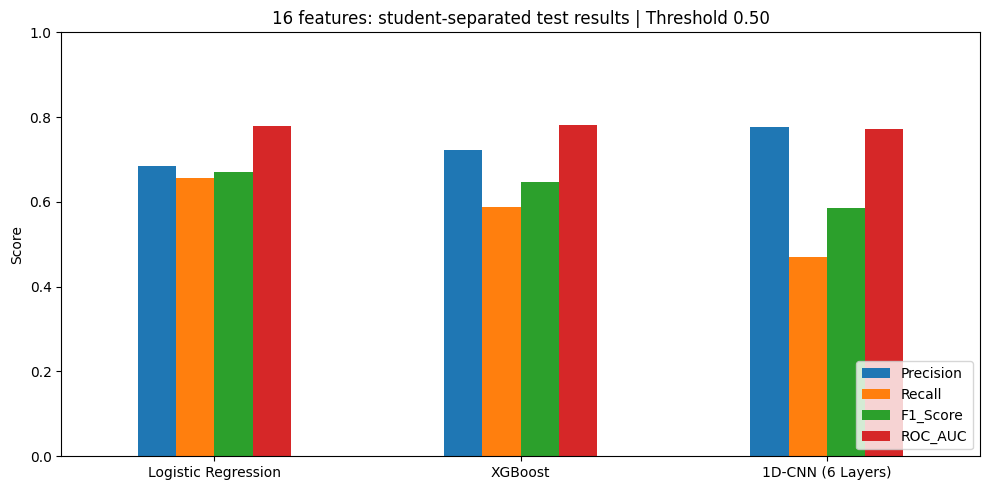

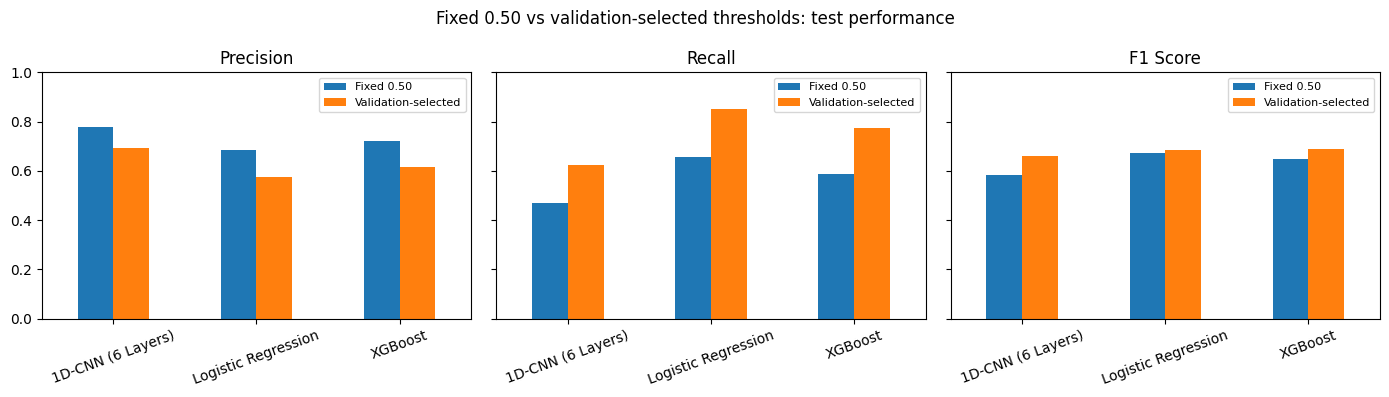

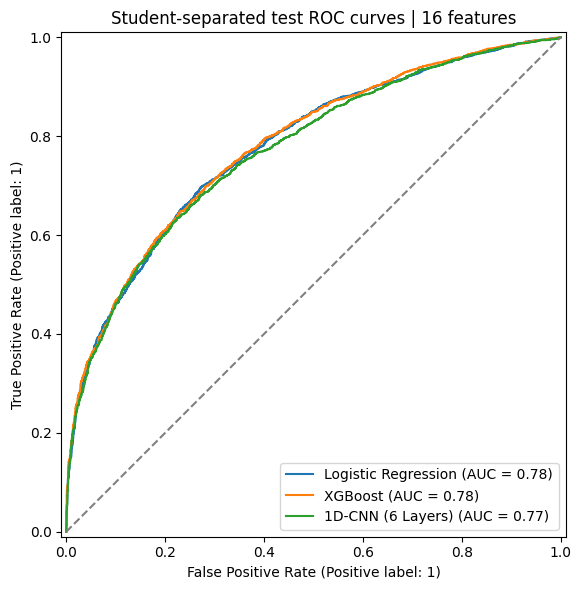

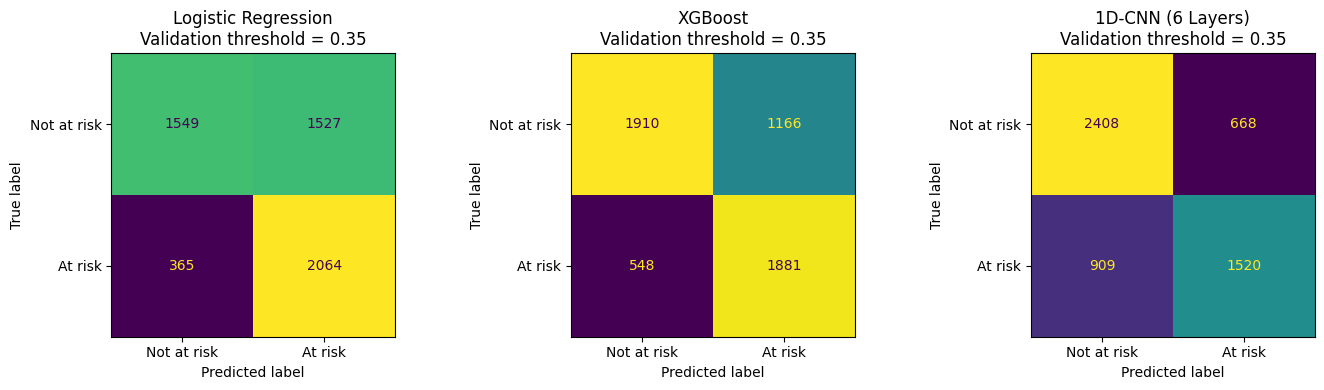

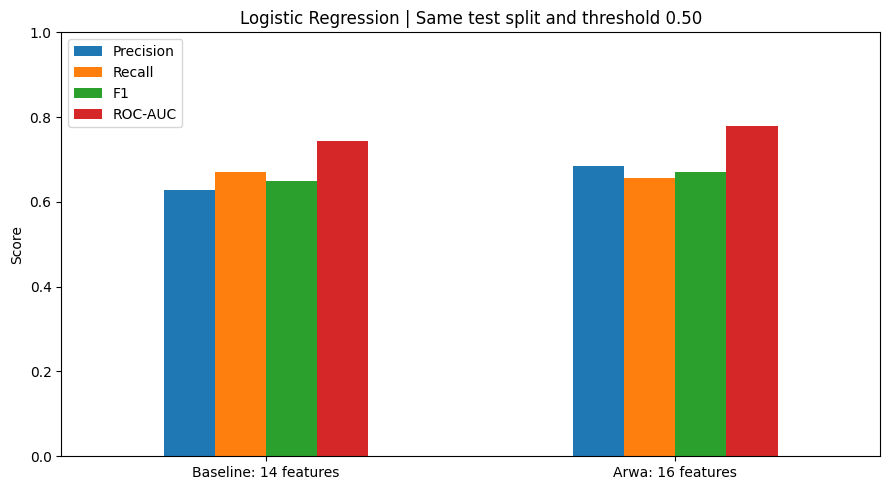

Figures and results saved. Downloading: OULAD_16Features_Corrected_Results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [7]:
import json
import platform
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
import io

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.metrics import (
    RocCurveDisplay, ConfusionMatrixDisplay
)
from google.colab import files

FIG16 = ARWA_OUT / "figures"
FIG16.mkdir(parents=True, exist_ok=True)

# 1. Compare all three models at the same fixed threshold.
fixed16 = results16[
    results16["Threshold_rule"].eq("Fixed 0.50")
].copy()

fig, ax = plt.subplots(figsize=(10, 5))
fixed16.set_index("Model")[[
    "Precision", "Recall", "F1_Score", "ROC_AUC"
]].plot.bar(ax=ax)
ax.set_ylim(0, 1)
ax.set_title("16 features: student-separated test results | Threshold 0.50")
ax.set_ylabel("Score")
ax.set_xlabel("")
ax.tick_params(axis="x", rotation=0)
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(FIG16 / "01_model_comparison.png", dpi=300)
plt.show()
plt.close(fig)

# 2. Show the precision / recall trade-off after threshold selection.
tuned16 = results16[
    results16["Threshold_rule"].eq("Validation-selected")
].copy()

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, metric in zip(axes, ["Precision", "Recall", "F1_Score"]):
    chart_data = results16.pivot(
        index="Model", columns="Threshold_rule", values=metric
    )
    chart_data.plot.bar(ax=ax)
    ax.set_title(metric.replace("_", " "))
    ax.set_ylim(0, 1)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=20)
    ax.legend(fontsize=8)
fig.suptitle("Fixed 0.50 vs validation-selected thresholds: test performance")
fig.tight_layout()
fig.savefig(FIG16 / "02_threshold_tradeoff.png", dpi=300)
plt.show()
plt.close(fig)

# 3. ROC curves use probabilities, so they do not depend on threshold.
probability_columns = {
    "Logistic Regression": "Logistic Regression_probability",
    "XGBoost": "XGBoost_probability",
    "1D-CNN (6 Layers)": "CNN_probability"
}
actual = predictions16["at_risk"].to_numpy()

fig, ax = plt.subplots(figsize=(7, 6))
for model_name, column in probability_columns.items():
    RocCurveDisplay.from_predictions(
        actual, predictions16[column].to_numpy(),
        name=model_name, ax=ax
    )
ax.plot([0, 1], [0, 1], "--", color="gray")
ax.set_title("Student-separated test ROC curves | 16 features")
fig.tight_layout()
fig.savefig(FIG16 / "03_roc_curves.png", dpi=300)
plt.show()
plt.close(fig)

# 4. Confusion matrices at the validation-selected thresholds.
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (model_name, column) in zip(
    axes, probability_columns.items()
):
    threshold = float(
        tuned16.loc[
            tuned16["Model"].eq(model_name), "Threshold"
        ].iloc[0]
    )
    ConfusionMatrixDisplay.from_predictions(
        actual,
        predictions16[column].to_numpy() >= threshold,
        display_labels=["Not at risk", "At risk"],
        colorbar=False,
        ax=ax
    )
    ax.set_title(f"{model_name}\nValidation threshold = {threshold:.2f}")
fig.tight_layout()
fig.savefig(FIG16 / "04_confusion_matrices.png", dpi=300)
plt.show()
plt.close(fig)

# 5. Compare LR feature sets at the SAME threshold.
with ZipFile(
    io.BytesIO(checkpoint_upload[checkpoint_name])
) as archive:
    baseline_name = next(
        name for name in archive.namelist()
        if name.endswith("04_model_comparison.csv")
    )
    baseline_results = pd.read_csv(archive.open(baseline_name))

baseline_lr = baseline_results.loc[
    baseline_results["Model"].eq("Logistic Regression")
].iloc[0]
new_lr = fixed16.loc[
    fixed16["Model"].eq("Logistic Regression")
].iloc[0]

feature_comparison = pd.DataFrame([
    {
        "Feature set": "Baseline: 14 features",
        "Precision": baseline_lr["Precision"],
        "Recall": baseline_lr["Recall"],
        "F1": baseline_lr["F1"],
        "ROC-AUC": baseline_lr["ROC-AUC"]
    },
    {
        "Feature set": "Arwa: 16 features",
        "Precision": new_lr["Precision"],
        "Recall": new_lr["Recall"],
        "F1": new_lr["F1_Score"],
        "ROC-AUC": new_lr["ROC_AUC"]
    }
])
feature_comparison.to_csv(
    ARWA_OUT / "baseline_vs_16features_LR.csv", index=False
)

fig, ax = plt.subplots(figsize=(9, 5))
feature_comparison.set_index("Feature set").plot.bar(ax=ax)
ax.set_ylim(0, 1)
ax.set_xlabel("")
ax.set_ylabel("Score")
ax.set_title("Logistic Regression | Same test split and threshold 0.50")
ax.tick_params(axis="x", rotation=0)
fig.tight_layout()
fig.savefig(FIG16 / "05_baseline_vs_16features.png", dpi=300)
plt.show()
plt.close(fig)

metadata16 = {
    "registrations": len(data16),
    "unique_students": int(data16["id_student"].nunique()),
    "training_registrations": len(train16_idx),
    "fit_registrations": len(fit16_idx),
    "validation_registrations": len(val16_idx),
    "test_registrations": len(test16_idx),
    "student_overlap": 0,
    "features": list(arwa.ALL_FEATURES),
    "split_source": "Exact saved corrected-baseline assignments",
    "validation": "First fold of training-only StratifiedGroupKFold; seed 42",
    "threshold_selection": "Maximum validation F1; grid 0.25 to 0.75 by 0.05",
    "final_training": "Refit on all training registrations after threshold selection",
    "cnn_epochs_per_stage": 25,
    "seed": 42,
    "python": platform.python_version(),
    "sklearn": sklearn.__version__,
    "torch": torch.__version__,
    "scope": (
        "Three-model comparison and validation-selected thresholds. "
        "New 16-feature CV, ablation, calibration, fairness and SHAP "
        "have not yet been rerun. These are not an exact paper replication."
    )
}
(ARWA_OUT / "corrected_run_metadata.json").write_text(
    json.dumps(metadata16, indent=2), encoding="utf-8"
)

bundle16 = Path("/content/OULAD_16Features_Corrected_Results.zip")
with ZipFile(bundle16, "w", ZIP_DEFLATED) as archive:
    for path in ARWA_OUT.rglob("*"):
        if path.is_file():
            archive.write(
                path, Path("corrected_results") / path.relative_to(ARWA_OUT)
            )
    for path in ARWA_DIR.glob("*.py"):
        archive.write(path, Path("arwa_original_source") / path.name)

print("Figures and results saved. Downloading:", bundle16.name)
files.download(str(bundle16))

In [8]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import roc_auc_score
import gc
import json
import time
import numpy as np
import pandas as pd
import torch

CV16_DIR = ARWA_OUT / "grouped_cv"
CV16_DIR.mkdir(parents=True, exist_ok=True)

# Use the training partition ONLY.
cv_data16 = data16.iloc[train16_idx].reset_index(drop=True)
cv_X16 = cv_data16[arwa.ALL_FEATURES].replace("?", np.nan)
cv_y16 = cv_data16["at_risk"].astype(int).to_numpy()
cv_groups16 = cv_data16["id_student"].to_numpy()

assert not set(cv_groups16).intersection(test_ids)

cv_splitter16 = StratifiedGroupKFold(
    n_splits=5, shuffle=True, random_state=42
)
cv_folds16 = list(
    cv_splitter16.split(cv_X16, cv_y16, groups=cv_groups16)
)

# Verify every fold before training.
cv_audit16 = []
for fold, (tr, va) in enumerate(cv_folds16, 1):
    overlap = len(
        set(cv_groups16[tr]).intersection(cv_groups16[va])
    )
    assert overlap == 0

    cv_audit16.append({
        "Fold": fold,
        "Training_registrations": len(tr),
        "Validation_registrations": len(va),
        "Student_overlap": overlap
    })

pd.DataFrame(cv_audit16).to_csv(
    CV16_DIR / "fold_audit.csv", index=False
)
display(pd.DataFrame(cv_audit16))

def cnn_predict_cv16(model, matrix):
    model.eval()
    probabilities = []
    with torch.no_grad():
        for start in range(0, len(matrix), 1024):
            batch = torch.as_tensor(
                np.asarray(matrix[start:start + 1024]),
                dtype=torch.float32
            ).unsqueeze(1).to(device16)
            probabilities.append(
                torch.sigmoid(model(batch)).cpu().numpy()
            )
    return np.concatenate(probabilities)

cv_records16 = []
cv_oof_parts16 = []

for fold, (tr, va) in enumerate(cv_folds16, 1):
    print(f"\n===== GROUPED FOLD {fold}/5 =====", flush=True)

    # Preprocessing is fitted separately inside each fold.
    fold_preprocessor = arwa.build_preprocessor(arwa.ALL_FEATURES)
    fold_X_train = fold_preprocessor.fit_transform(cv_X16.iloc[tr])
    fold_X_val = fold_preprocessor.transform(cv_X16.iloc[va])

    for model_name, factory in [
        ("Logistic Regression", arwa.get_lr_model),
        ("XGBoost", arwa.get_xgb_model),
        ("1D-CNN (6 Layers)", None)
    ]:
        slug = {
            "Logistic Regression": "LR",
            "XGBoost": "XGB",
            "1D-CNN (6 Layers)": "CNN"
        }[model_name]

        metric_path = CV16_DIR / f"fold_{fold}_{slug}_metrics.json"
        prediction_path = CV16_DIR / f"fold_{fold}_{slug}_predictions.csv"

        if metric_path.exists() and prediction_path.exists():
            record = json.loads(metric_path.read_text())
            fold_predictions = pd.read_csv(prediction_path)
            print(f"Already completed: {model_name}", flush=True)

        else:
            print(f"Training: {model_name}", flush=True)
            started = time.perf_counter()

            if factory is not None:
                fold_model = factory()
                fold_model.fit(fold_X_train, cv_y16[tr])
                train_probability = fold_model.predict_proba(
                    fold_X_train
                )[:, 1]
                val_probability = fold_model.predict_proba(
                    fold_X_val
                )[:, 1]
            else:
                fold_model, val_probability = fit_cnn16(
                    fold_X_train,
                    cv_y16[tr],
                    fold_X_val,
                    f"CV fold {fold}/5"
                )
                train_probability = cnn_predict_cv16(
                    fold_model, fold_X_train
                )

            val_metrics = arwa.compute_metrics(
                cv_y16[va], val_probability, threshold=0.50
            )
            train_auc = roc_auc_score(
                cv_y16[tr], train_probability
            )

            record = {
                "Model": model_name,
                "Fold": fold,
                "Threshold": 0.50,
                "Train_AUC": float(train_auc),
                "Validation_AUC": float(val_metrics["ROC_AUC"]),
                "AUC_Gap": float(train_auc - val_metrics["ROC_AUC"]),
                "Validation_F1": float(val_metrics["F1_Score"]),
                "Validation_Precision": float(val_metrics["Precision"]),
                "Validation_Recall": float(val_metrics["Recall"]),
                "Validation_Balanced_Acc": float(val_metrics["Balanced_Acc"]),
                "Student_overlap": 0,
                "Fit_and_predict_seconds": time.perf_counter() - started
            }

            fold_predictions = cv_data16.iloc[va][
                KEYS + ["at_risk"]
            ].copy()
            fold_predictions["Model"] = model_name
            fold_predictions["Fold"] = fold
            fold_predictions["probability"] = val_probability

            # Save predictions first; metrics mark completion.
            fold_predictions.to_csv(prediction_path, index=False)
            metric_path.write_text(
                json.dumps(record, indent=2), encoding="utf-8"
            )

            print(
                f"Saved {model_name} | Fold {fold} | "
                f"F1={record['Validation_F1']:.3f} | "
                f"AUC={record['Validation_AUC']:.3f}",
                flush=True
            )
            del fold_model
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

        cv_records16.append(record)
        cv_oof_parts16.append(fold_predictions)

        # Update consolidated results after every completed model.
        pd.DataFrame(cv_records16).to_csv(
            CV16_DIR / "grouped_cv_fold_results.csv", index=False
        )

cv_details16 = pd.DataFrame(cv_records16)
cv_oof16 = pd.concat(cv_oof_parts16, ignore_index=True)

assert len(cv_details16) == 15
for name, group in cv_oof16.groupby("Model"):
    assert len(group) == len(cv_data16)
    assert not group.duplicated(KEYS).any()

cv_oof16.to_csv(
    CV16_DIR / "grouped_cv_out_of_fold_predictions.csv", index=False
)

cv_summary16 = cv_details16.groupby("Model", sort=False).agg(
    F1_mean=("Validation_F1", "mean"),
    F1_SD=("Validation_F1", "std"),
    AUC_mean=("Validation_AUC", "mean"),
    AUC_SD=("Validation_AUC", "std"),
    Precision_mean=("Validation_Precision", "mean"),
    Recall_mean=("Validation_Recall", "mean"),
    Train_AUC_mean=("Train_AUC", "mean"),
    AUC_gap_mean=("AUC_Gap", "mean")
).reset_index()

cv_summary16.to_csv(
    CV16_DIR / "grouped_cv_summary.csv", index=False
)

metadata_path = ARWA_OUT / "corrected_run_metadata.json"
if metadata_path.exists():
    metadata = json.loads(metadata_path.read_text())
    metadata["grouped_cv_completed"] = {
        "folds": 5,
        "models": 3,
        "partition": "Training only",
        "threshold": 0.50,
        "cnn_epochs_per_fold": 25,
        "student_overlap_each_fold": 0
    }
    metadata["scope"] = (
        "Main comparison, validation-selected thresholds and "
        "training-only grouped CV completed. Other extensions "
        "are recorded separately as they are completed."
    )
    metadata_path.write_text(
        json.dumps(metadata, indent=2), encoding="utf-8"
    )

display(cv_summary16.round(3))
print("\nGROUPED CV COMPLETED: 15 model-fold runs saved.", flush=True)

,Fold,Training_registrations,Validation_registrations,Student_overlap
0,1,17620,4397,0
1,2,17585,4432,0
2,3,17595,4422,0
3,4,17645,4372,0
4,5,17623,4394,0



===== GROUPED FOLD 1/5 =====
Training: Logistic Regression
Saved Logistic Regression | Fold 1 | F1=0.651 | AUC=0.780
Training: XGBoost
Saved XGBoost | Fold 1 | F1=0.636 | AUC=0.778
Training: 1D-CNN (6 Layers)
CV fold 1/5: epoch 1/25 | loss 0.5963 | 7s
CV fold 1/5: epoch 5/25 | loss 0.5589 | 40s
CV fold 1/5: epoch 10/25 | loss 0.5502 | 83s
CV fold 1/5: epoch 15/25 | loss 0.5457 | 122s
CV fold 1/5: epoch 20/25 | loss 0.5400 | 162s
CV fold 1/5: epoch 25/25 | loss 0.5355 | 202s
Saved 1D-CNN (6 Layers) | Fold 1 | F1=0.637 | AUC=0.782

===== GROUPED FOLD 2/5 =====
Training: Logistic Regression
Saved Logistic Regression | Fold 2 | F1=0.668 | AUC=0.777
Training: XGBoost
Saved XGBoost | Fold 2 | F1=0.656 | AUC=0.781
Training: 1D-CNN (6 Layers)
CV fold 2/5: epoch 1/25 | loss 0.5957 | 7s
CV fold 2/5: epoch 5/25 | loss 0.5567 | 41s
CV fold 2/5: epoch 10/25 | loss 0.5492 | 82s
CV fold 2/5: epoch 15/25 | loss 0.5437 | 121s
CV fold 2/5: epoch 20/25 | loss 0.5400 | 163s
CV fold 2/5: epoch 25/25 | los

,Model,F1_mean,F1_SD,AUC_mean,AUC_SD,Precision_mean,Recall_mean,Train_AUC_mean,AUC_gap_mean
0,Logistic Regression,0.665,0.009,0.779,0.004,0.682,0.649,0.780,0.002
1,XGBoost,0.648,0.008,0.779,0.003,0.728,0.585,0.830,0.051
2,1D-CNN (6 Layers),0.638,0.016,0.776,0.005,0.729,0.570,0.804,0.028



GROUPED CV COMPLETED: 15 model-fold runs saved.


In [9]:
import json
import time
import gc
import numpy as np
import pandas as pd
import torch

ABL16_DIR = ARWA_OUT / "ablation"
ABL16_DIR.mkdir(parents=True, exist_ok=True)

# Explicit feature groups.
profile16 = arwa.CATEGORICAL_FEATURES + ["has_previous_attempt"]
assessment16 = [
    c for c in arwa.ALL_FEATURES
    if "assessment" in c or c == "early_late_submission_count"
]
vle16 = [
    c for c in arwa.ALL_FEATURES
    if c not in profile16 and c not in assessment16
]

ablation_subsets16 = {
    "Full 16 features": list(arwa.ALL_FEATURES),
    "Without early assessments": [
        c for c in arwa.ALL_FEATURES if c not in assessment16
    ],
    "Without VLE activity": [
        c for c in arwa.ALL_FEATURES if c not in vle16
    ],
    "Profile and course only": profile16,
    "VLE and assessments only": [
        c for c in arwa.ALL_FEATURES if c not in profile16
    ]
}

assert len(profile16) == 5
assert len(assessment16) == 5
assert len(vle16) == 6

print("Feature groups:", flush=True)
for label, columns in ablation_subsets16.items():
    print(label, ":", len(columns), "features", flush=True)

# Verify that grouped CV fold 1 used the same validation registrations.
expected_validation16 = data16.iloc[val16_idx][KEYS].copy()
fold1_lr_file = (
    ARWA_OUT / "grouped_cv" / "fold_1_LR_predictions.csv"
)

reuse_full16 = False
if fold1_lr_file.exists():
    fold1_keys = pd.read_csv(fold1_lr_file)[KEYS]
    key_check = expected_validation16.merge(
        fold1_keys, on=KEYS, how="outer",
        validate="one_to_one", indicator=True
    )
    reuse_full16 = key_check["_merge"].eq("both").all()

print("Can reuse full-feature CV fold 1:", reuse_full16, flush=True)

ablation_records16 = []

for subset_number, (subset_name, columns) in enumerate(
    ablation_subsets16.items(), 1
):
    print(
        f"\n===== ABLATION {subset_number}/5: {subset_name} =====",
        flush=True
    )

    # Fit preprocessing ONLY on the fitting partition.
    subset_prep = arwa.build_preprocessor(columns)
    subset_X_fit = subset_prep.fit_transform(
        X16.iloc[fit16_idx][columns]
    )
    subset_X_val = subset_prep.transform(
        X16.iloc[val16_idx][columns]
    )

    for model_name, factory, slug in [
        ("Logistic Regression", arwa.get_lr_model, "LR"),
        ("XGBoost", arwa.get_xgb_model, "XGB"),
        ("1D-CNN (6 Layers)", None, "CNN")
    ]:
        prefix = f"subset_{subset_number}_{slug}"
        metrics_file = ABL16_DIR / f"{prefix}_metrics.json"
        predictions_file = ABL16_DIR / f"{prefix}_predictions.csv"

        if metrics_file.exists() and predictions_file.exists():
            record = json.loads(metrics_file.read_text())
            print("Already saved:", model_name, flush=True)

        else:
            started = time.perf_counter()
            reused = False

            if subset_number == 1 and reuse_full16:
                source = (
                    ARWA_OUT / "grouped_cv" /
                    f"fold_1_{slug}_predictions.csv"
                )
                if source.exists():
                    saved = pd.read_csv(source)
                    aligned = expected_validation16.merge(
                        saved[KEYS + ["probability"]],
                        on=KEYS, how="left", validate="one_to_one"
                    )
                    assert aligned["probability"].notna().all()
                    probability = aligned["probability"].to_numpy()
                    reused = True

            if not reused:
                print("Training:", model_name, flush=True)

                if factory is not None:
                    subset_model = factory()
                    subset_model.fit(
                        subset_X_fit, y16[fit16_idx]
                    )
                    probability = subset_model.predict_proba(
                        subset_X_val
                    )[:, 1]
                else:
                    subset_model, probability = fit_cnn16(
                        subset_X_fit,
                        y16[fit16_idx],
                        subset_X_val,
                        f"Ablation {subset_number}/5"
                    )

            metrics = arwa.compute_metrics(
                y16[val16_idx], probability, threshold=0.50
            )
            record = {
                "Feature_subset": subset_name,
                "Raw_feature_count": len(columns),
                "Model": model_name,
                "Evaluation_partition": "Validation only",
                "Threshold": 0.50,
                **{k: float(v) for k, v in metrics.items()},
                "Reused_CV_fold_1": bool(reused),
                "Seconds_this_cell": time.perf_counter() - started
            }

            prediction_table = data16.iloc[val16_idx][
                KEYS + ["at_risk"]
            ].copy()
            prediction_table["probability"] = probability
            prediction_table.to_csv(predictions_file, index=False)

            metrics_file.write_text(
                json.dumps(record, indent=2), encoding="utf-8"
            )

            print(
                f"Saved {model_name}: "
                f"F1={metrics['F1_Score']:.3f}, "
                f"AUC={metrics['ROC_AUC']:.3f}"
                + (" [reused]" if reused else ""),
                flush=True
            )

            if not reused:
                del subset_model
                gc.collect()
                if torch.cuda.is_available():
                    torch.cuda.empty_cache()

        ablation_records16.append(record)
        pd.DataFrame(ablation_records16).to_csv(
            ABL16_DIR / "ablation_validation_results.csv",
            index=False
        )

ablation_results16 = pd.DataFrame(ablation_records16)
assert len(ablation_results16) == 15

(ABL16_DIR / "feature_groups.json").write_text(
    json.dumps(ablation_subsets16, indent=2),
    encoding="utf-8"
)

display(ablation_results16[[
    "Feature_subset", "Raw_feature_count", "Model",
    "Precision", "Recall", "F1_Score", "ROC_AUC"
]].round(3))

print(
    "\nABLATION COMPLETED. Results use validation only; "
    "test data were not used for feature selection.",
    flush=True
)

Feature groups:
Full 16 features : 16 features
Without early assessments : 11 features
Without VLE activity : 10 features
Profile and course only : 5 features
VLE and assessments only : 11 features
Can reuse full-feature CV fold 1: True

===== ABLATION 1/5: Full 16 features =====
Saved Logistic Regression: F1=0.651, AUC=0.780 [reused]
Saved XGBoost: F1=0.636, AUC=0.778 [reused]
Saved 1D-CNN (6 Layers): F1=0.637, AUC=0.782 [reused]

===== ABLATION 2/5: Without early assessments =====
Training: Logistic Regression
Saved Logistic Regression: F1=0.625, AUC=0.735
Training: XGBoost
Saved XGBoost: F1=0.575, AUC=0.729
Training: 1D-CNN (6 Layers)
Ablation 2/5: epoch 1/25 | loss 0.6232 | 11s
Ablation 2/5: epoch 5/25 | loss 0.5951 | 38s
Ablation 2/5: epoch 10/25 | loss 0.5907 | 70s
Ablation 2/5: epoch 15/25 | loss 0.5857 | 104s
Ablation 2/5: epoch 20/25 | loss 0.5825 | 136s
Ablation 2/5: epoch 25/25 | loss 0.5799 | 168s
Saved 1D-CNN (6 Layers): F1=0.586, AUC=0.727

===== ABLATION 3/5: Without VLE

,Feature_subset,Raw_feature_count,Model,Precision,Recall,F1_Score,ROC_AUC
0,Full 16 features,16,Logistic Regression,0.660,0.641,0.651,0.780
1,Full 16 features,16,XGBoost,0.703,0.580,0.636,0.778
2,Full 16 features,16,1D-CNN (6 Layers),0.707,0.580,0.637,0.782
3,Without early assessments,11,Logistic Regression,0.604,0.648,0.625,0.735
4,Without early assessments,11,XGBoost,0.642,0.520,0.575,0.729
5,Without early assessments,11,1D-CNN (6 Layers),0.637,0.542,0.586,0.727
6,Without VLE activity,10,Logistic Regression,0.670,0.564,0.613,0.746
7,Without VLE activity,10,XGBoost,0.722,0.503,0.593,0.747
8,Without VLE activity,10,1D-CNN (6 Layers),0.734,0.511,0.602,0.745
9,Profile and course only,5,Logistic Regression,0.524,0.582,0.552,0.635



ABLATION COMPLETED. Results use validation only; test data were not used for feature selection.



Logistic Regression: calibration on fitting data...
Threshold fixed at 0.35. Refitting calibration on all training data...
Logistic Regression saved in 45.5s.

XGBoost: calibration on fitting data...
Threshold fixed at 0.35. Refitting calibration on all training data...
XGBoost saved in 23.1s.


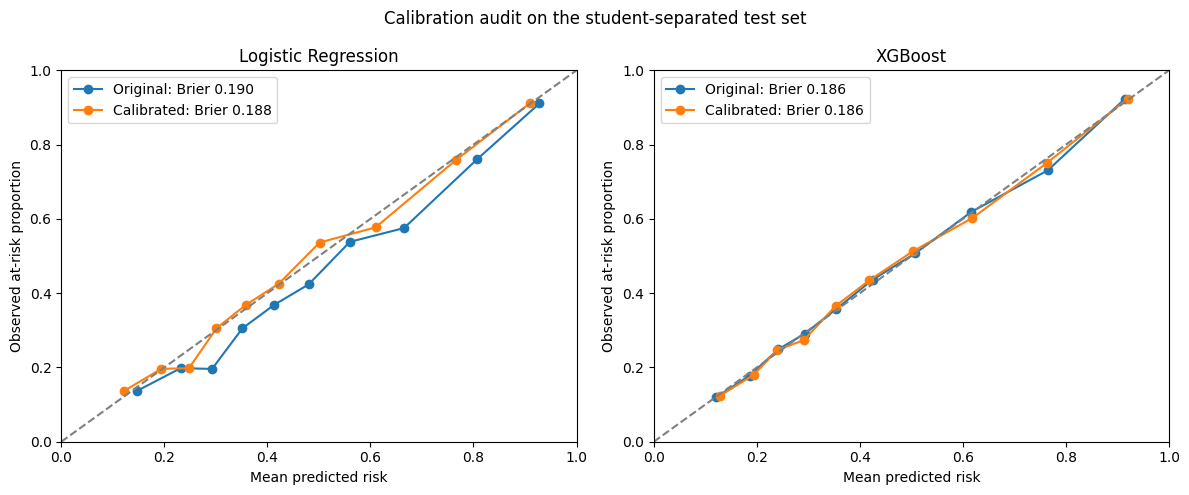


CALIBRATED TEST RESULTS


,Model,Calibration_method,Threshold_rule,Threshold,Precision,Recall,F1_Score,ROC_AUC,Brier_Score
0,Logistic Regression,sigmoid,Fixed 0.50,0.50,0.721,0.572,0.638,0.778,0.188
1,Logistic Regression,sigmoid,Validation-selected,0.35,0.610,0.779,0.684,0.778,0.188
2,XGBoost,isotonic,Fixed 0.50,0.50,0.722,0.576,0.641,0.781,0.186
3,XGBoost,isotonic,Validation-selected,0.35,0.618,0.774,0.687,0.781,0.186



SUBGROUP ERROR AUDIT


,Attribute,Group,Model,Registrations,Threshold,FNR,FPR
0,code_module,AAA,Logistic Regression,141,0.35,0.634,0.140
1,code_module,AAA,XGBoost,141,0.35,0.634,0.120
2,code_module,BBB,Logistic Regression,1318,0.35,0.271,0.381
3,code_module,BBB,XGBoost,1318,0.35,0.246,0.392
4,code_module,CCC,Logistic Regression,687,0.35,0.140,0.443
5,code_module,CCC,XGBoost,687,0.35,0.164,0.417
6,code_module,DDD,Logistic Regression,1071,0.35,0.118,0.467
7,code_module,DDD,XGBoost,1071,0.35,0.127,0.422
8,code_module,EEE,Logistic Regression,497,0.35,0.362,0.312
9,code_module,EEE,XGBoost,497,0.35,0.400,0.255



CALIBRATION AND SUBGROUP AUDIT COMPLETED. All outputs saved.


In [10]:
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score,
    precision_score, recall_score, f1_score,
    roc_auc_score, brier_score_loss, confusion_matrix
)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import joblib
import time

CAL16_DIR = ARWA_OUT / "calibration_and_subgroups"
CAL16_DIR.mkdir(parents=True, exist_ok=True)

def safe_metrics16(actual, probability, threshold):
    actual = np.asarray(actual, dtype=int)
    probability = np.asarray(probability)
    predicted = (probability >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        actual, predicted, labels=[0, 1]
    ).ravel()
    both_classes = len(np.unique(actual)) == 2

    return {
        "Accuracy": accuracy_score(actual, predicted),
        "Balanced_Acc": (
            balanced_accuracy_score(actual, predicted)
            if both_classes else np.nan
        ),
        "Precision": precision_score(
            actual, predicted, zero_division=0
        ),
        "Recall": (
            tp / (tp + fn) if tp + fn else np.nan
        ),
        "F1_Score": f1_score(
            actual, predicted, zero_division=0
        ),
        "ROC_AUC": (
            roc_auc_score(actual, probability)
            if both_classes else np.nan
        ),
        "Brier_Score": brier_score_loss(actual, probability),
        "FNR": fn / (fn + tp) if fn + tp else np.nan,
        "FPR": fp / (fp + tn) if fp + tn else np.nan,
        "Alert_rate": float(predicted.mean()),
        "TN": int(tn), "FP": int(fp),
        "FN": int(fn), "TP": int(tp)
    }

def grouped_calibrator16(factory, method, row_indices):
    frame = X16.iloc[row_indices]
    target = y16[row_indices]
    student_groups = (
        data16.iloc[row_indices]["id_student"].to_numpy()
    )

    splitter = StratifiedGroupKFold(
        n_splits=5, shuffle=True, random_state=42
    )
    folds = list(
        splitter.split(frame, target, groups=student_groups)
    )

    for train_local, cal_local in folds:
        assert not set(
            student_groups[train_local]
        ).intersection(student_groups[cal_local])

    # Preprocessing fits separately within every calibration fold.
    pipeline = Pipeline([
        ("preprocessor", arwa.build_preprocessor(arwa.ALL_FEATURES)),
        ("model", factory())
    ])

    calibrated = CalibratedClassifierCV(
        estimator=pipeline,
        method=method,
        cv=folds,
        ensemble=True,
        n_jobs=1
    )
    return calibrated.fit(frame, target)

calibrated16 = {}
calibration_rows16 = []
calibration_search16 = []
calibration_predictions16 = (
    data16.iloc[test16_idx][KEYS + ["at_risk"]].copy()
)

# Methods follow Arwa's choices, fixed before evaluating test data.
for name, factory, method in [
    ("Logistic Regression", arwa.get_lr_model, "sigmoid"),
    ("XGBoost", arwa.get_xgb_model, "isotonic")
]:
    print(f"\n{name}: calibration on fitting data...", flush=True)
    started = time.perf_counter()

    selection_calibrator = grouped_calibrator16(
        factory, method, fit16_idx
    )
    validation_probability = selection_calibrator.predict_proba(
        X16.iloc[val16_idx]
    )[:, 1]

    thresholds = np.round(np.arange(0.25, 0.751, 0.05), 2)
    validation_scores = [
        f1_score(
            y16[val16_idx],
            validation_probability >= threshold,
            zero_division=0
        )
        for threshold in thresholds
    ]
    threshold = float(
        thresholds[np.argmax(validation_scores)]
    )

    for candidate, score in zip(thresholds, validation_scores):
        calibration_search16.append({
            "Model": name,
            "Calibration_method": method,
            "Threshold": candidate,
            "Validation_F1": score
        })

    print(
        f"Threshold fixed at {threshold:.2f}. "
        "Refitting calibration on all training data...",
        flush=True
    )

    final_calibrator = grouped_calibrator16(
        factory, method, train16_idx
    )
    test_probability = final_calibrator.predict_proba(
        X16.iloc[test16_idx]
    )[:, 1]

    calibrated16[name] = {
        "model": final_calibrator,
        "threshold": threshold,
        "method": method,
        "test_probability": test_probability
    }

    for rule, used_threshold in [
        ("Fixed 0.50", 0.50),
        ("Validation-selected", threshold)
    ]:
        calibration_rows16.append({
            "Model": name,
            "Calibration_method": method,
            "Threshold_rule": rule,
            "Threshold": used_threshold,
            **safe_metrics16(
                y16[test16_idx],
                test_probability,
                used_threshold
            )
        })

    calibration_predictions16[
        f"{name}_calibrated_probability"
    ] = test_probability

    joblib.dump(
        {
            "model": final_calibrator,
            "threshold": threshold,
            "method": method
        },
        CAL16_DIR / f"{name.replace(' ', '_')}_calibrated.joblib"
    )
    print(
        f"{name} saved in "
        f"{time.perf_counter() - started:.1f}s.",
        flush=True
    )

calibration_results16 = pd.DataFrame(calibration_rows16)
calibration_results16.to_csv(
    CAL16_DIR / "calibrated_test_results.csv", index=False
)
pd.DataFrame(calibration_search16).to_csv(
    CAL16_DIR / "validation_threshold_search.csv", index=False
)
calibration_predictions16.to_csv(
    CAL16_DIR / "calibrated_test_predictions.csv", index=False
)

# Reliability plots: test evaluation only, no method selection.
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
actual_test16 = y16[test16_idx]

for ax, name in zip(
    axes, ["Logistic Regression", "XGBoost"]
):
    raw_probability = predictions16[
        f"{name}_probability"
    ].to_numpy()
    calibrated_probability = calibrated16[name]["test_probability"]

    for label, probability in [
        ("Original", raw_probability),
        ("Calibrated", calibrated_probability)
    ]:
        observed, predicted = calibration_curve(
            actual_test16, probability,
            n_bins=10, strategy="quantile"
        )
        ax.plot(
            predicted, observed, marker="o",
            label=f"{label}: Brier "
                  f"{brier_score_loss(actual_test16, probability):.3f}"
        )

    ax.plot([0, 1], [0, 1], "--", color="gray")
    ax.set_title(name)
    ax.set_xlabel("Mean predicted risk")
    ax.set_ylabel("Observed at-risk proportion")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.legend()

fig.suptitle("Calibration audit on the student-separated test set")
fig.tight_layout()
fig.savefig(
    CAL16_DIR / "calibration_curves.png",
    dpi=300, bbox_inches="tight"
)
plt.show()
plt.close(fig)

# Subgroup audit: each model uses its OWN validation-selected threshold.
test_frame16 = data16.iloc[test16_idx].reset_index(drop=True)
subgroup_rows16 = []

for attribute in ["code_module", "disability", "highest_education"]:
    for value, subgroup in test_frame16.groupby(
        attribute, dropna=False
    ):
        positions = subgroup.index.to_numpy()
        actual_subgroup = actual_test16[positions]

        for name, details in calibrated16.items():
            subgroup_rows16.append({
                "Attribute": attribute,
                "Group": str(value),
                "Registrations": len(positions),
                "Unique_students": int(
                    subgroup["id_student"].nunique()
                ),
                "At_risk_count": int(actual_subgroup.sum()),
                "Not_at_risk_count": int(
                    len(actual_subgroup) - actual_subgroup.sum()
                ),
                "Small_group_under_15": len(positions) < 15,
                "Model": name,
                "Threshold": details["threshold"],
                **safe_metrics16(
                    actual_subgroup,
                    details["test_probability"][positions],
                    details["threshold"]
                )
            })

subgroup_results16 = pd.DataFrame(subgroup_rows16)
subgroup_results16.to_csv(
    CAL16_DIR / "subgroup_error_audit.csv", index=False
)

print("\nCALIBRATED TEST RESULTS")
display(calibration_results16[[
    "Model", "Calibration_method", "Threshold_rule",
    "Threshold", "Precision", "Recall",
    "F1_Score", "ROC_AUC", "Brier_Score"
]].round(3))

print("\nSUBGROUP ERROR AUDIT")
display(subgroup_results16[[
    "Attribute", "Group", "Model",
    "Registrations", "Threshold", "FNR", "FPR"
]].round(3))

print(
    "\nCALIBRATION AND SUBGROUP AUDIT COMPLETED. "
    "All outputs saved.",
    flush=True
)

Preparing model explanations...
Computing XGBoost TreeSHAP...


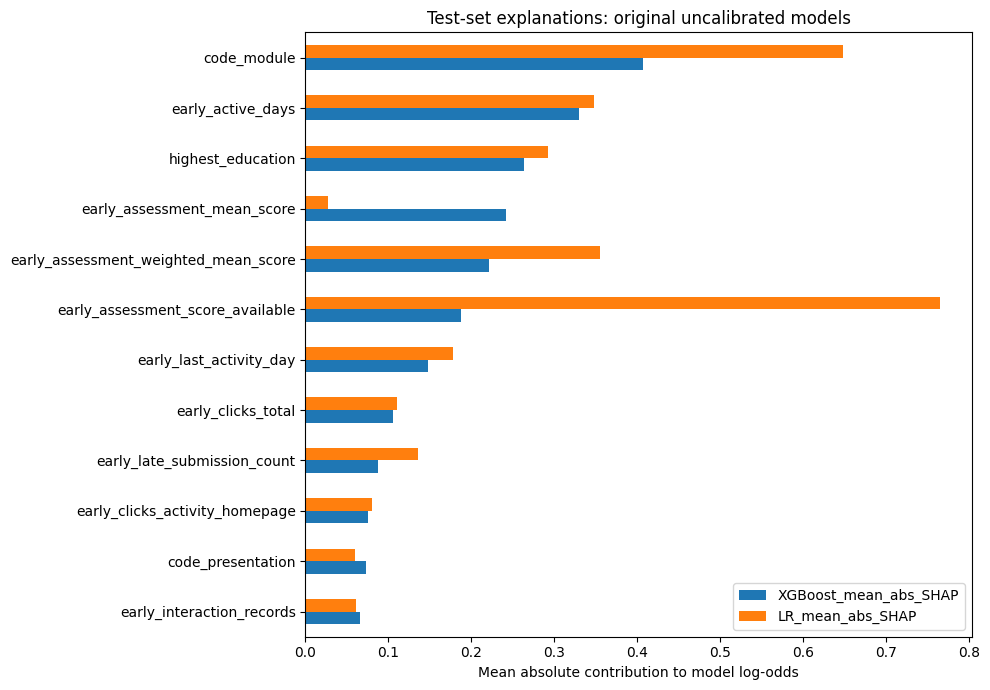

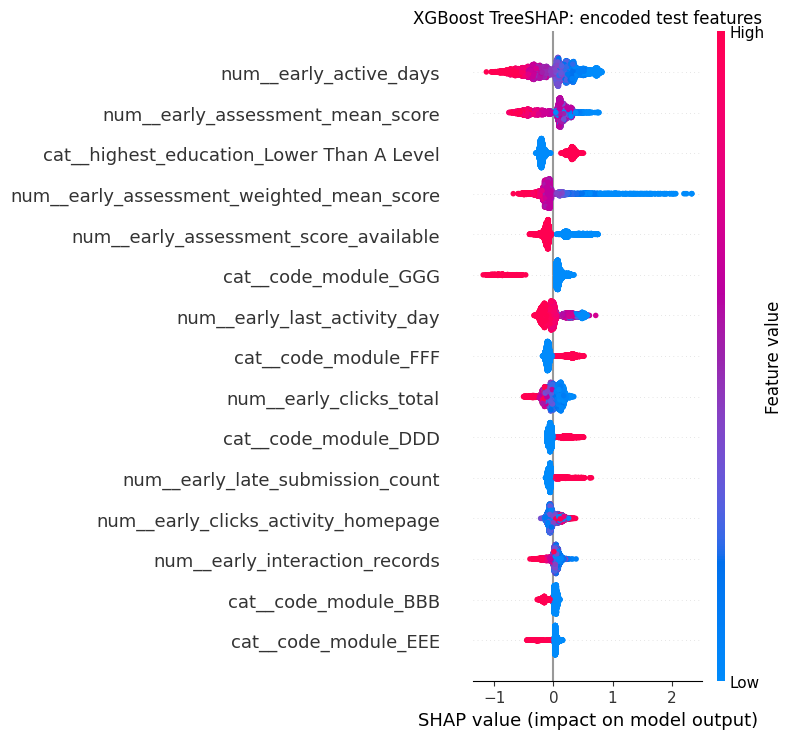

Computing training-only SHAP dependence curves...


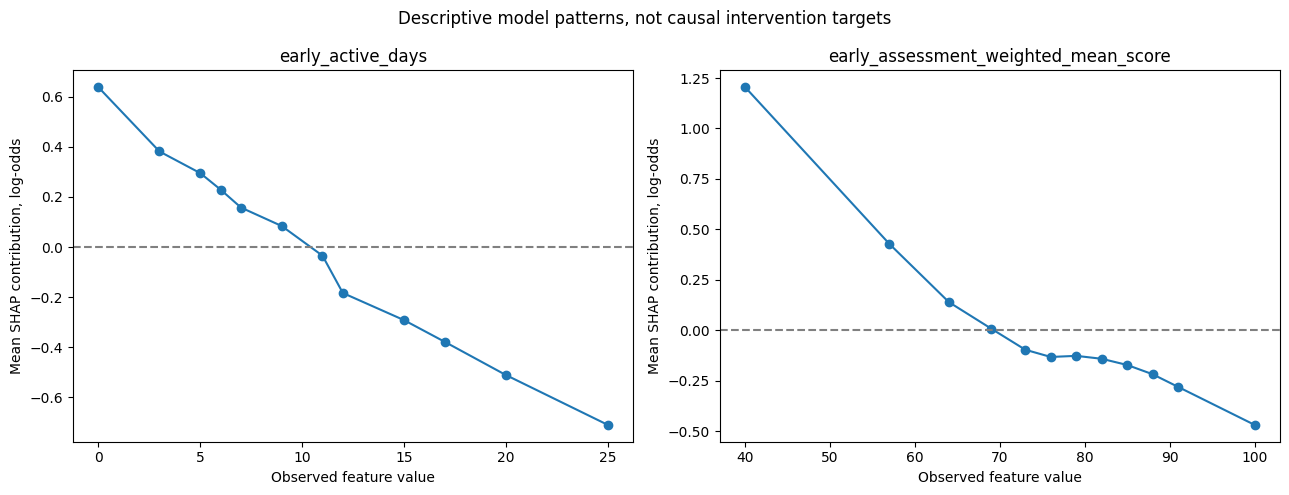

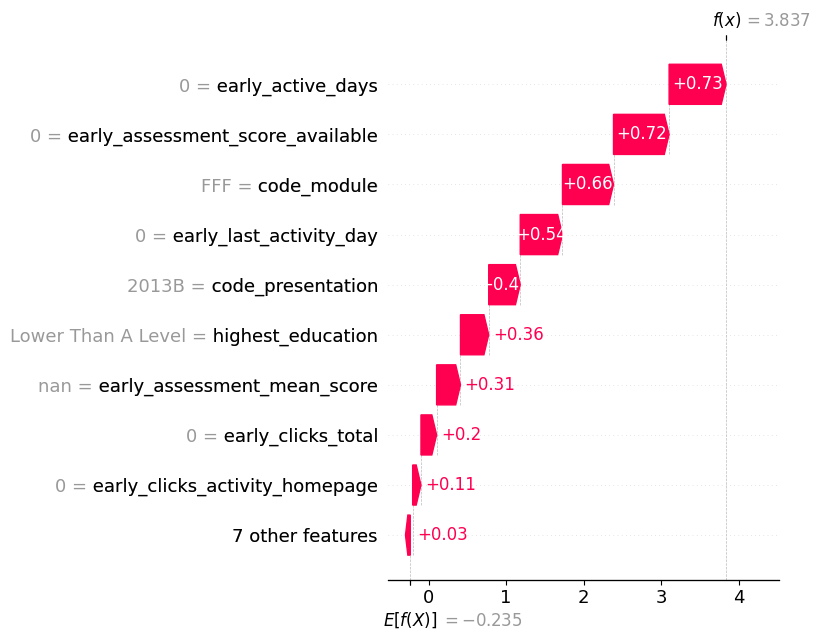

,Feature,XGBoost_mean_abs_SHAP,LR_mean_abs_SHAP
12,code_module,0.4070,0.6481
2,early_active_days,0.3300,0.3475
14,highest_education,0.2630,0.2926
0,early_assessment_mean_score,0.2420,0.0277
6,early_assessment_weighted_mean_score,0.2211,0.3546
7,early_assessment_score_available,0.1870,0.7644
8,early_last_activity_day,0.1475,0.1777
3,early_clicks_total,0.1053,0.1098
9,early_late_submission_count,0.0872,0.1353
4,early_clicks_activity_homepage,0.0757,0.0796


SHAP AND OUTREACH LIST COMPLETED. Flagged test registrations: 3047


In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
import shap
import json

SHAP16_DIR = ARWA_OUT / "shap_and_outreach"
SHAP16_DIR.mkdir(parents=True, exist_ok=True)

print("Preparing model explanations...", flush=True)

prep_xgb16, raw_xgb16 = models16["XGBoost"]
prep_lr16, raw_lr16 = models16["Logistic Regression"]

xgb_test_matrix16 = np.asarray(
    prep_xgb16.transform(X16.iloc[test16_idx])
)
xgb_train_matrix16 = np.asarray(
    prep_xgb16.transform(X16.iloc[train16_idx])
)
lr_test_matrix16 = np.asarray(
    prep_lr16.transform(X16.iloc[test16_idx])
)
lr_train_matrix16 = np.asarray(
    prep_lr16.transform(X16.iloc[train16_idx])
)

xgb_names16 = list(prep_xgb16.get_feature_names_out())
lr_names16 = list(prep_lr16.get_feature_names_out())

# XGBoost's native exact TreeSHAP contributions, in raw log-odds.
print("Computing XGBoost TreeSHAP...", flush=True)
xgb_test_contributions16 = raw_xgb16.get_booster().predict(
    xgb.DMatrix(xgb_test_matrix16), pred_contribs=True
)
xgb_shap16 = xgb_test_contributions16[:, :-1]
xgb_base16 = xgb_test_contributions16[:, -1]

# Independent linear attribution around the training mean.
lr_background_mean16 = lr_train_matrix16.mean(axis=0)
lr_shap16 = (
    lr_test_matrix16 - lr_background_mean16
) * raw_lr16.coef_[0]
lr_base16 = float(
    raw_lr16.intercept_[0]
    + lr_background_mean16 @ raw_lr16.coef_[0]
)

def sigmoid16(values):
    return 1 / (1 + np.exp(-np.clip(values, -700, 700)))

# Verify that explanations reconstruct their own model predictions.
assert np.allclose(
    sigmoid16(xgb_base16 + xgb_shap16.sum(axis=1)),
    raw_xgb16.predict_proba(xgb_test_matrix16)[:, 1],
    atol=1e-5
)
assert np.allclose(
    sigmoid16(lr_base16 + lr_shap16.sum(axis=1)),
    raw_lr16.predict_proba(lr_test_matrix16)[:, 1],
    atol=1e-6
)

# Aggregate one-hot columns back to the 16 original features.
def parent_feature16(encoded_name):
    for feature in sorted(arwa.ALL_FEATURES, key=len, reverse=True):
        if encoded_name == f"num__{feature}":
            return feature
        if encoded_name.startswith(f"cat__{feature}_"):
            return feature
    raise ValueError("Unmapped feature: " + encoded_name)

def aggregate_shap16(values, encoded_names):
    result = pd.DataFrame(
        0.0,
        index=np.arange(len(values)),
        columns=arwa.ALL_FEATURES
    )
    for index, encoded_name in enumerate(encoded_names):
        result[parent_feature16(encoded_name)] += values[:, index]
    return result

xgb_parent_shap16 = aggregate_shap16(xgb_shap16, xgb_names16)
lr_parent_shap16 = aggregate_shap16(lr_shap16, lr_names16)

importance16 = pd.DataFrame({
    "Feature": arwa.ALL_FEATURES,
    "XGBoost_mean_abs_SHAP": (
        xgb_parent_shap16.abs().mean().reindex(arwa.ALL_FEATURES).values
    ),
    "LR_mean_abs_SHAP": (
        lr_parent_shap16.abs().mean().reindex(arwa.ALL_FEATURES).values
    )
}).sort_values("XGBoost_mean_abs_SHAP", ascending=False)

importance16.to_csv(
    SHAP16_DIR / "global_parent_feature_importance.csv", index=False
)

fig, ax = plt.subplots(figsize=(10, 7))
importance16.head(12).sort_values(
    "XGBoost_mean_abs_SHAP"
).plot.barh(
    x="Feature",
    y=["XGBoost_mean_abs_SHAP", "LR_mean_abs_SHAP"],
    ax=ax
)
ax.set_xlabel("Mean absolute contribution to model log-odds")
ax.set_ylabel("")
ax.set_title("Test-set explanations: original uncalibrated models")
fig.tight_layout()
fig.savefig(
    SHAP16_DIR / "01_global_importance.png", dpi=300
)
plt.show()
plt.close(fig)

# Beeswarm uses encoded / standardized inputs.
shap.summary_plot(
    xgb_shap16, xgb_test_matrix16,
    feature_names=xgb_names16,
    max_display=15, show=False
)
plt.title("XGBoost TreeSHAP: encoded test features")
plt.tight_layout()
plt.savefig(
    SHAP16_DIR / "02_xgboost_beeswarm.png",
    dpi=300, bbox_inches="tight"
)
plt.show()
plt.close()

# Derive descriptive SHAP zero-crossings on TRAINING data only.
print("Computing training-only SHAP dependence curves...", flush=True)
train_contributions16 = raw_xgb16.get_booster().predict(
    xgb.DMatrix(xgb_train_matrix16), pred_contribs=True
)[:, :-1]
train_parent_shap16 = aggregate_shap16(
    train_contributions16, xgb_names16
)
train_raw16 = data16.iloc[train16_idx].reset_index(drop=True)

crossing_rows16 = []
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, feature in zip(axes, [
    "early_active_days",
    "early_assessment_weighted_mean_score"
]):
    valid = train_raw16[feature].notna().to_numpy()

    if feature == "early_assessment_weighted_mean_score":
        valid &= (
            train_raw16["early_assessment_score_available"]
            .eq(1).to_numpy()
        )

    curve_data = pd.DataFrame({
        "value": train_raw16.loc[valid, feature].to_numpy(),
        "SHAP": train_parent_shap16.loc[valid, feature].to_numpy()
    })
    curve_data["bin"] = pd.qcut(
        curve_data["value"], q=12, duplicates="drop"
    )
    curve = curve_data.groupby("bin", observed=True).agg(
        Value_median=("value", "median"),
        SHAP_mean=("SHAP", "mean"),
        Count=("SHAP", "size")
    ).dropna().reset_index(drop=True)

    curve.to_csv(
        SHAP16_DIR / f"dependence_{feature}.csv", index=False
    )
    ax.plot(curve["Value_median"], curve["SHAP_mean"], marker="o")
    ax.axhline(0, color="gray", linestyle="--")
    ax.set_title(feature)
    ax.set_xlabel("Observed feature value")
    ax.set_ylabel("Mean SHAP contribution, log-odds")

    found = False
    for i in range(len(curve) - 1):
        x1, y1 = curve.loc[i, ["Value_median", "SHAP_mean"]]
        x2, y2 = curve.loc[i + 1, ["Value_median", "SHAP_mean"]]
        if y1 > 0 and y2 <= 0:
            crossing = float(x1 - y1 * (x2 - x1) / (y2 - y1))
            crossing_rows16.append({
                "Feature": feature,
                "Descriptive_zero_crossing": crossing,
                "Partition": "Training only",
                "Meaning": "Model contribution changes from positive to nonpositive"
            })
            found = True

    if not found:
        crossing_rows16.append({
            "Feature": feature,
            "Descriptive_zero_crossing": np.nan,
            "Partition": "Training only",
            "Meaning": "No positive-to-nonpositive crossing detected"
        })

fig.suptitle("Descriptive model patterns, not causal intervention targets")
fig.tight_layout()
fig.savefig(
    SHAP16_DIR / "03_training_dependence.png",
    dpi=300, bbox_inches="tight"
)
plt.show()
plt.close(fig)

pd.DataFrame(crossing_rows16).to_csv(
    SHAP16_DIR / "descriptive_training_zero_crossings.csv",
    index=False
)

# Outreach list: probabilities and SHAP explain the SAME raw XGBoost model.
outreach_threshold16 = float(results16.loc[
    results16["Model"].eq("XGBoost")
    & results16["Threshold_rule"].eq("Validation-selected"),
    "Threshold"
].iloc[0])

outreach16 = data16.iloc[test16_idx][
    KEYS + ["at_risk"]
].reset_index(drop=True)

outreach16["risk_probability"] = raw_xgb16.predict_proba(
    xgb_test_matrix16
)[:, 1]
outreach16["validation_selected_threshold"] = outreach_threshold16
outreach16["flag_for_review"] = (
    outreach16["risk_probability"] >= outreach_threshold16
)
outreach16["explained_model"] = "Original uncalibrated XGBoost"

for rank in range(3):
    driver_names, driver_values = [], []
    for values in xgb_parent_shap16.to_numpy():
        positive = np.flatnonzero(values > 0)
        ordered = positive[np.argsort(values[positive])[::-1]]
        index = ordered[rank] if len(ordered) > rank else None
        driver_names.append(
            arwa.ALL_FEATURES[index] if index is not None else ""
        )
        driver_values.append(
            float(values[index]) if index is not None else np.nan
        )
    outreach16[f"risk_driver_{rank + 1}"] = driver_names
    outreach16[f"risk_driver_{rank + 1}_SHAP"] = driver_values

outreach16.to_csv(
    SHAP16_DIR / "test_outreach_review_list_all.csv", index=False
)
outreach16[outreach16["flag_for_review"]].sort_values(
    "risk_probability", ascending=False
).to_csv(
    SHAP16_DIR / "test_outreach_flagged.csv", index=False
)

# One local explanation for the highest predicted test risk.
example16 = int(outreach16["risk_probability"].to_numpy().argmax())
explanation16 = shap.Explanation(
    values=xgb_parent_shap16.iloc[example16].to_numpy(),
    base_values=float(xgb_base16[example16]),
    data=data16.iloc[test16_idx].iloc[example16][
        arwa.ALL_FEATURES
    ].to_numpy(),
    feature_names=arwa.ALL_FEATURES
)
shap.plots.waterfall(explanation16, max_display=10, show=False)
plt.tight_layout()
plt.savefig(
    SHAP16_DIR / "04_local_explanation.png",
    dpi=300, bbox_inches="tight"
)
plt.show()
plt.close()

(SHAP16_DIR / "interpretation_notes.txt").write_text(
    "SHAP explains the original uncalibrated LR and XGBoost models. "
    "XGBoost uses native tree-path-dependent TreeSHAP. "
    "LR uses independent linear attribution around the training mean. "
    "One-hot contributions sum to their parent feature before aggregation. "
    "Zero-crossings use training data and describe model behaviour only. "
    "They are not validated causal or intervention thresholds. "
    "The outreach list is a held-out retrospective demonstration. "
    "No notifications were sent and no intervention effect was measured.",
    encoding="utf-8"
)

display(importance16.round(4))
print(
    "SHAP AND OUTREACH LIST COMPLETED. "
    "Flagged test registrations:",
    int(outreach16["flag_for_review"].sum()),
    flush=True
)

In [13]:
from zipfile import ZipFile
import io
import numpy as np
import pandas as pd
import json

TIME16_DIR = ARWA_OUT / "week4_6_8"
TIME16_DIR.mkdir(parents=True, exist_ok=True)

# Registration dates from the verified baseline checkpoint.
with ZipFile(
    io.BytesIO(checkpoint_upload[checkpoint_name])
) as archive:
    cohort_file = next(
        name for name in archive.namelist()
        if name.endswith("day28_model_data.csv")
    )
    baseline_cohort16 = pd.read_csv(archive.open(cohort_file))

cohort_dates16 = baseline_cohort16[
    KEYS + ["date_registration", "date_unregistration"]
].copy()

for column in ["date_registration", "date_unregistration"]:
    cohort_dates16[column] = pd.to_numeric(
        cohort_dates16[column], errors="coerce"
    )

partition_map16 = data16[
    KEYS + ["partition", "at_risk"]
].rename(columns={"at_risk": "baseline_target"})

temporal_data16 = {}
temporal_audit16 = []

with ZipFile(io.BytesIO(uploaded[zip_name])) as archive:
    for day, week in [(28, 4), (42, 6), (56, 8)]:
        suffix = f"oulad_day{day}_week{week}_features.csv"
        member = next(
            name for name in archive.namelist()
            if name.endswith(suffix)
        )
        frame = pd.read_csv(archive.open(member))
        assert not frame.duplicated(KEYS).any()

        # Follow the original day-28 cohort.
        # Preserve each student's original train/test assignment.
        frame = frame.merge(
            partition_map16,
            on=KEYS, how="inner", validate="one_to_one"
        ).merge(
            cohort_dates16,
            on=KEYS, how="left", validate="one_to_one"
        )

        assert frame["at_risk"].eq(frame["baseline_target"]).all()

        # Match the corrected baseline's boundary convention:
        # exclude withdrawal on or before the prediction day.
        eligible = (
            (
                frame["date_registration"].isna()
                | frame["date_registration"].le(day)
            )
            & (
                frame["date_unregistration"].isna()
                | frame["date_unregistration"].gt(day)
            )
        )
        frame = frame.loc[eligible].reset_index(drop=True)

        assert frame["early_active_days"].dropna().between(0, day).all()
        assert frame["early_last_activity_day"].dropna().lt(day).all()

        training = frame["partition"].eq("train")
        testing = frame["partition"].eq("test")

        shared = len(
            set(frame.loc[training, "id_student"])
            & set(frame.loc[testing, "id_student"])
        )
        assert shared == 0

        if day == 28:
            assert len(frame) == 27522
            assert int(training.sum()) == 22017
            assert int(testing.sum()) == 5505

        temporal_data16[day] = frame
        frame.to_csv(
            TIME16_DIR / f"day{day}_verified_features.csv",
            index=False
        )

        temporal_audit16.append({
            "Week": week,
            "Prediction_day": day,
            "Registrations": len(frame),
            "Training": int(training.sum()),
            "Test": int(testing.sum()),
            "At_risk_percentage": frame["at_risk"].mean() * 100,
            "Student_overlap": shared
        })

temporal_audit16 = pd.DataFrame(temporal_audit16)
temporal_audit16.to_csv(
    TIME16_DIR / "cohort_audit.csv", index=False
)

(TIME16_DIR / "comparison_notes.json").write_text(
    json.dumps({
        "design": "Separate longitudinal experiment",
        "features": "Arwa's consistent week4/week6/week8 feature files",
        "split": "Inherited corrected baseline student assignments",
        "cohort": (
            "Follow day-28 cohort, retaining only registrations "
            "still eligible at each later prediction day"
        ),
        "interpretation": (
            "Both observed information and eligible cohort change. "
            "Differences do not isolate the effect of additional weeks."
        ),
        "threshold": "Fixed 0.50 for all horizons",
        "missing_registration_dates": "Retained, as in corrected baseline",
        "assessment_limitation": (
            "Submission dates bound the observation window. "
            "Actual grade-release timestamps are unavailable."
        )
    }, indent=2),
    encoding="utf-8"
)

display(temporal_audit16.round(2))
print("TEMPORAL DATA READY. No models trained in this cell.")

,Week,Prediction_day,Registrations,Training,Test,At_risk_percentage,Student_overlap
0,4,28,27522,22017,5505,44.12,0
1,6,42,27008,21592,5416,43.06,0
2,8,56,26506,21201,5305,41.98,0


TEMPORAL DATA READY. No models trained in this cell.



===== WEEK 4: DAY 28 =====
Training: Logistic Regression
Saved Logistic Regression: F1=0.663, AUC=0.765
Training: XGBoost
Saved XGBoost: F1=0.649, AUC=0.782
Training: 1D-CNN (6 Layers)
Week 4: epoch 1/25 | loss 0.5932 | 22s
Week 4: epoch 5/25 | loss 0.5544 | 64s
Week 4: epoch 10/25 | loss 0.5452 | 114s
Week 4: epoch 15/25 | loss 0.5445 | 164s
Week 4: epoch 20/25 | loss 0.5393 | 213s
Week 4: epoch 25/25 | loss 0.5344 | 260s
Saved 1D-CNN (6 Layers): F1=0.566, AUC=0.774

===== WEEK 6: DAY 42 =====
Training: Logistic Regression
Saved Logistic Regression: F1=0.667, AUC=0.783
Training: XGBoost
Saved XGBoost: F1=0.670, AUC=0.801
Training: 1D-CNN (6 Layers)
Week 6: epoch 1/25 | loss 0.5725 | 10s
Week 6: epoch 5/25 | loss 0.5274 | 49s
Week 6: epoch 10/25 | loss 0.5179 | 94s
Week 6: epoch 15/25 | loss 0.5121 | 142s
Week 6: epoch 20/25 | loss 0.5074 | 189s
Week 6: epoch 25/25 | loss 0.5046 | 235s
Saved 1D-CNN (6 Layers): F1=0.661, AUC=0.793

===== WEEK 8: DAY 56 =====
Training: Logistic Regressi

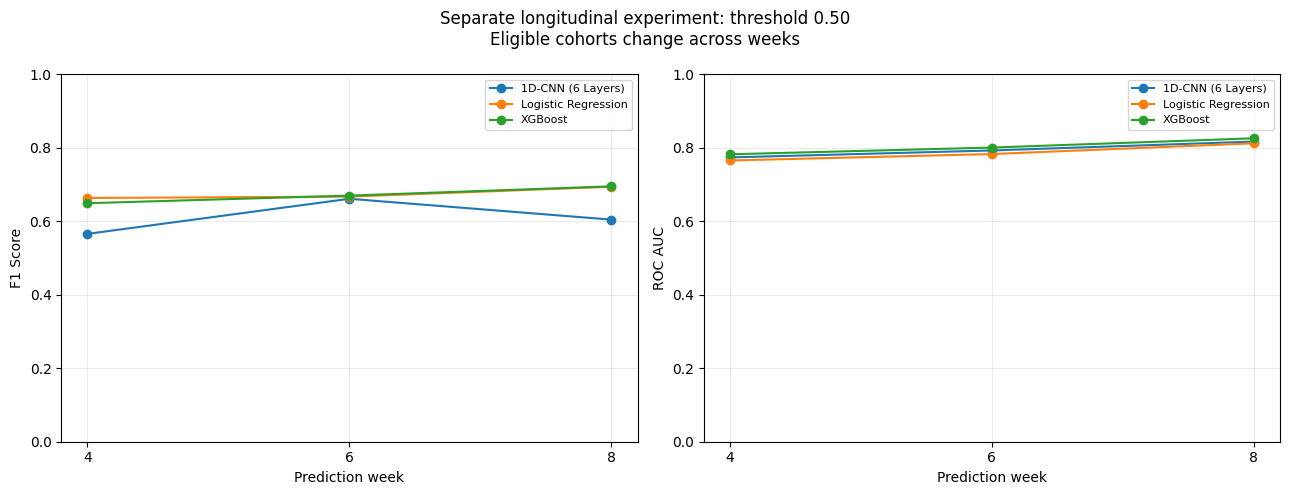

,Week,Model,Test_registrations,Precision,Recall,F1_Score,ROC_AUC
0,4,Logistic Regression,5505,0.664,0.663,0.663,0.765
1,4,XGBoost,5505,0.721,0.590,0.649,0.782
2,4,1D-CNN (6 Layers),5505,0.774,0.446,0.566,0.774
3,6,Logistic Regression,5416,0.672,0.662,0.667,0.783
4,6,XGBoost,5416,0.745,0.608,0.670,0.801
5,6,1D-CNN (6 Layers),5416,0.731,0.604,0.661,0.793
6,8,Logistic Regression,5305,0.699,0.689,0.694,0.812
7,8,XGBoost,5305,0.775,0.630,0.695,0.826
8,8,1D-CNN (6 Layers),5305,0.848,0.470,0.605,0.817



COMPLETION CHECK
main_three_model_comparison : SAVED
grouped_cv : SAVED
ablation : SAVED
calibration : SAVED
subgroup_audit : SAVED
SHAP_and_outreach_list : SAVED
week4_6_8_comparison : SAVED

Downloading: OULAD_Corrected_All_Analyses.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [14]:
import json
import time
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import joblib
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
from google.colab import files

temporal_records16 = []

for day, frame in temporal_data16.items():
    week = day // 7
    print(f"\n===== WEEK {week}: DAY {day} =====", flush=True)

    train_mask = frame["partition"].eq("train").to_numpy()
    test_mask = frame["partition"].eq("test").to_numpy()

    horizon_X = frame[arwa.ALL_FEATURES].replace("?", np.nan)
    horizon_y = frame["at_risk"].astype(int).to_numpy()

    horizon_prep = arwa.build_preprocessor(arwa.ALL_FEATURES)
    horizon_X_train = horizon_prep.fit_transform(
        horizon_X.loc[train_mask]
    )
    horizon_X_test = horizon_prep.transform(
        horizon_X.loc[test_mask]
    )

    joblib.dump(
        horizon_prep,
        TIME16_DIR / f"day{day}_preprocessor.joblib"
    )

    for model_name, factory, slug in [
        ("Logistic Regression", arwa.get_lr_model, "LR"),
        ("XGBoost", arwa.get_xgb_model, "XGB"),
        ("1D-CNN (6 Layers)", None, "CNN")
    ]:
        metric_file = TIME16_DIR / f"day{day}_{slug}_metrics.json"
        prediction_file = TIME16_DIR / f"day{day}_{slug}_predictions.csv"

        if metric_file.exists() and prediction_file.exists():
            record = json.loads(metric_file.read_text())
            print("Already completed:", model_name, flush=True)

        else:
            print("Training:", model_name, flush=True)
            started = time.perf_counter()

            if factory is not None:
                horizon_model = factory()
                horizon_model.fit(
                    horizon_X_train, horizon_y[train_mask]
                )
                probability = horizon_model.predict_proba(
                    horizon_X_test
                )[:, 1]
                joblib.dump(
                    horizon_model,
                    TIME16_DIR / f"day{day}_{slug}_model.joblib"
                )

            else:
                horizon_model, probability = fit_cnn16(
                    horizon_X_train,
                    horizon_y[train_mask],
                    horizon_X_test,
                    f"Week {week}"
                )
                torch.save({
                    "state_dict": {
                        key: value.detach().cpu()
                        for key, value in horizon_model.state_dict().items()
                    },
                    "num_features": horizon_X_train.shape[1],
                    "epochs": 25,
                    "seed": 42,
                    "threshold": 0.50
                }, TIME16_DIR / f"day{day}_CNN_model.pt")

            metrics = safe_metrics16(
                horizon_y[test_mask], probability, 0.50
            )
            record = {
                "Week": week,
                "Prediction_day": day,
                "Model": model_name,
                "Threshold": 0.50,
                "Training_registrations": int(train_mask.sum()),
                "Test_registrations": int(test_mask.sum()),
                **{k: float(v) for k, v in metrics.items()},
                "Fit_and_predict_seconds": time.perf_counter() - started
            }

            horizon_predictions = frame.loc[
                test_mask, KEYS + ["at_risk"]
            ].copy()
            horizon_predictions["probability"] = probability
            horizon_predictions.to_csv(
                prediction_file, index=False
            )
            metric_file.write_text(
                json.dumps(record, indent=2), encoding="utf-8"
            )

            print(
                f"Saved {model_name}: "
                f"F1={metrics['F1_Score']:.3f}, "
                f"AUC={metrics['ROC_AUC']:.3f}",
                flush=True
            )
            del horizon_model
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

        temporal_records16.append(record)
        pd.DataFrame(temporal_records16).to_csv(
            TIME16_DIR / "week4_6_8_model_comparison.csv",
            index=False
        )

temporal_results16 = pd.DataFrame(temporal_records16)
assert len(temporal_results16) == 9

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, metric in zip(axes, ["F1_Score", "ROC_AUC"]):
    for model_name, group in temporal_results16.groupby("Model"):
        group = group.sort_values("Week")
        ax.plot(
            group["Week"], group[metric],
            marker="o", label=model_name
        )
    ax.set_xticks([4, 6, 8])
    ax.set_xlabel("Prediction week")
    ax.set_ylabel(metric.replace("_", " "))
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)

fig.suptitle(
    "Separate longitudinal experiment: threshold 0.50\n"
    "Eligible cohorts change across weeks"
)
fig.tight_layout()
fig.savefig(
    TIME16_DIR / "week4_6_8_comparison.png",
    dpi=300, bbox_inches="tight"
)
plt.show()
plt.close(fig)

display(temporal_results16[[
    "Week", "Model", "Test_registrations",
    "Precision", "Recall", "F1_Score", "ROC_AUC"
]].round(3))

# Record completion from the actual saved outputs.
completed_checks16 = {
    "main_three_model_comparison": (
        ARWA_OUT / "main_comparison_16features.csv"
    ).exists(),
    "grouped_cv": (
        ARWA_OUT / "grouped_cv/grouped_cv_summary.csv"
    ).exists(),
    "ablation": (
        ARWA_OUT / "ablation/ablation_validation_results.csv"
    ).exists(),
    "calibration": (
        ARWA_OUT / "calibration_and_subgroups/calibrated_test_results.csv"
    ).exists(),
    "subgroup_audit": (
        ARWA_OUT / "calibration_and_subgroups/subgroup_error_audit.csv"
    ).exists(),
    "SHAP_and_outreach_list": (
        ARWA_OUT / "shap_and_outreach/test_outreach_flagged.csv"
    ).exists(),
    "week4_6_8_comparison": len(temporal_results16) == 9
}

metadata_file = ARWA_OUT / "corrected_run_metadata.json"
metadata = json.loads(metadata_file.read_text())
metadata["completed_analyses"] = completed_checks16
metadata["scope"] = (
    "Corrected three-model comparison, validation-selected thresholds, "
    "grouped CV, validation ablation, grouped probability calibration, "
    "subgroup error audit, SHAP, retrospective outreach lists and "
    "a separate week4/week6/week8 experiment. "
    "No notifications were sent. No intervention effect was tested. "
    "This is an adaptation, not an exact paper replication."
)
metadata_file.write_text(
    json.dumps(metadata, indent=2), encoding="utf-8"
)

final_bundle16 = Path("/content/OULAD_Corrected_All_Analyses.zip")
with ZipFile(final_bundle16, "w", ZIP_DEFLATED) as archive:
    for path in ARWA_OUT.rglob("*"):
        if path.is_file():
            archive.write(
                path,
                Path("corrected_results") / path.relative_to(ARWA_OUT)
            )
    for path in ARWA_DIR.glob("*.py"):
        archive.write(
            path, Path("arwa_original_source") / path.name
        )

print("\nCOMPLETION CHECK")
for analysis, completed in completed_checks16.items():
    print(analysis, ":", "SAVED" if completed else "MISSING")

print("\nDownloading:", final_bundle16.name, flush=True)
files.download(str(final_bundle16))